# Data Cleaning: NYC Street Pothole Work Orders + NYC Weather

**Pertanyaan analisis:** bagaimana kondisi cuaca (hujan, salju, siklus beku-cair) berkaitan dengan jumlah laporan lubang jalan dan kecepatan perbaikannya di tiap borough NYC?

## Sumber Data & Sitasi

| Dataset | File | Level data | Sumber | Lisensi |
|---|---|---|---|---|
| Street Pothole Work Orders – Closed | `street_pothole_work_orders.csv` | 1 baris = 1 work order perbaikan lubang jalan | NYC Department of Transportation, via [NYC Open Data](https://data.cityofnewyork.us/Transportation/Street-Pothole-Work-Orders-Closed-Dataset-/x9wy-ing4) ([metadata resmi PDF](https://www.nyc.gov/html/dot/downloads/pdf/street-potholes-metadata.pdf)) | Open Data (NYC Open Data Terms of Use) |
| Cuaca harian NYC 2018–2024 | `weather_nyc.csv` | 1 baris = 1 hari | [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) (berbasis reanalisis ERA5, ECMWF) | CC-BY-4.0 — Zippenfenig, P. (2023). *Open-Meteo.com Weather API* [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.7970649 |
| Verifikasi cuaca (referensi) | `reference/noaa_centralpark_2018_2024.csv` | 1 baris = 1 hari | [NOAA NCEI GHCN-Daily](https://www.ncei.noaa.gov/access/services/data/v1), stasiun Central Park (`USW00094728`) | Data publik pemerintah AS (public domain) |

> Data pothole diverifikasi cocok dengan sumber resmi: jumlah baris (±409 ribu) dan kolom (15) di NYC Open Data sesuai dengan file `street_pothole_work_orders.csv`, dan **metadata resmi mengonfirmasi struktur `OFT`** (kode 6-byte On/From/To) yang sebelumnya diturunkan secara empiris di bagian 6 `data_integration.ipynb`.

Notebook ini berisi:
1. **Setup**
2. **Load data** dengan tipe data yang benar
3. **Data understanding & profiling** kedua dataset
4. **Daftar masalah kualitas data**, yang menjadi dasar langkah cleaning berikutnya

> Data raw **tidak pernah diubah**. Semua transformasi dilakukan di kode.

## 0. Setup

In [1]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    import missingno as msno
except ModuleNotFoundError:          # Google Colab belum punya missingno
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "missingno"], check=True)
    import missingno as msno

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold"})

# Repo GitHub menyimpan versi .csv.gz (agar muat di bawah batas 100 MB GitHub).
# pandas membaca .gz secara transparan, jadi cukup pilih file mana yang tersedia.
DATA_POTHOLE = next(f for f in [Path("street_pothole_work_orders.csv"),
                                Path("street_pothole_work_orders.csv.gz")] if f.exists())
DATA_WEATHER = Path("weather_nyc.csv")
OUT_DIR, FIG_DIR = Path("output"), Path("figures")
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

# Log jumlah baris & kolom di setiap langkah, dipakai untuk funnel chart di akhir cleaning
log_steps = []
def log(step, df):
    log_steps.append({"step": step, "rows": len(df), "cols": df.shape[1]})
    print(f"[{step}] rows={len(df):,} cols={df.shape[1]}")

# Register masalah kualitas data yang ditemukan selama profiling
issues = []
def issue(dataset, column, problem, n_rows, plan):
    issues.append({"dataset": dataset, "column": column, "problem": problem,
                   "n_rows": int(n_rows), "planned_action": plan})

## 1. Load Data

### 1.1 Kenapa perlu hati-hati saat membaca CSV pothole?

- `OFT` adalah **kode** segmen jalan 18 digit, bukan besaran angka. Tanpa `dtype`, pandas membacanya sebagai `int64`. Nilainya masih utuh, tetapi (1) kode diperlakukan sebagai angka yang bisa dijumlah/dirata-rata, (2) jika ada satu nilai kosong kolom berubah jadi `float64` dan digit belakangnya hilang (float hanya presisi ±15–16 digit), dan (3) Excel menampilkannya sebagai notasi ilmiah dan hanya menyimpan 15 digit. Karena itu kolom ini dibaca sebagai **string**.
- `DefNum` dan `HouseNum` juga merupakan kode/ID (misalnya `42-25A`), bukan angka, sehingga ikut dibaca sebagai string.
- `the_geom` dan `SpecLoc` berisi **koma di dalam tanda kutip**, sehingga file harus dibaca dengan parser CSV yang memahami quoting (pandas), bukan dipisah manual per koma.

In [2]:
pothole_raw = pd.read_csv(
    DATA_POTHOLE,
    dtype={"OFT": "string", "DefNum": "string", "HouseNum": "string"},
)
weather_raw = pd.read_csv(DATA_WEATHER)

print("Pothole :", pothole_raw.shape, "| OFT utuh 18 digit:", (pothole_raw["OFT"].str.len() == 18).all())
print("Weather :", weather_raw.shape)
log("raw", pothole_raw)

Pothole : (410488, 15) | OFT utuh 18 digit: True
Weather : (2557, 6)
[raw] rows=410,488 cols=15


## 2. Data Understanding: Pothole Work Orders

### 2.1 Struktur & contoh data

In [3]:
pothole_raw.info(memory_usage="deep")
pothole_raw.drop(columns="the_geom").head()

<class 'pandas.DataFrame'>
RangeIndex: 410488 entries, 0 to 410487
Data columns (total 15 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   the_geom    410488 non-null  str    
 1   DefNum      410488 non-null  string 
 2   InitBy      410488 non-null  str    
 3   HouseNum    249132 non-null  string 
 4   OFT         410488 non-null  string 
 5   OnFaceName  409770 non-null  str    
 6   OnPrimName  410411 non-null  str    
 7   FrmPrimNam  410458 non-null  str    
 8   ToPrimName  410382 non-null  str    
 9   SpecLoc     141426 non-null  str    
 10  Boro        410488 non-null  str    
 11  Source      410488 non-null  str    
 12  RptDate     410488 non-null  str    
 13  RptClosed   410488 non-null  str    
 14  Shape_Leng  410488 non-null  float64
dtypes: float64(1), str(11), string(3)
memory usage: 155.2 MB


,DefNum,InitBy,HouseNum,OFT,OnFaceName,OnPrimName,FrmPrimNam,ToPrimName,SpecLoc,Boro,Source,RptDate,RptClosed,Shape_Leng
0,DB2004041154,YRD,<NA>,373480377030377030,ROCKAWAY PY,ROCKAWAY PARKWAY,BELT PARKWAY,BELT PARKWAY,NaN,B,YRD,2004/02/08 00:00:00,2023/01/27 00:00:00,557.69
1,DB2004287021,CSC,<NA>,318630377030377030,BEDFORD AV,BEDFORD AVENUE,BELT PARKWAY,BELT PARKWAY,SB ON BEDFORD_UNDERNEATH OVERPASS,B,CTZ,2004/10/13 00:00:00,2013/02/14 00:00:00,109.12
2,DB2006085009,CSC,<NA>,306380308480308530,13 AV,13 AVENUE,38 STREET,39 STREET,I/F/O B16 BUS STOP,B,CTZ,2006/03/26 00:00:00,2014/10/11 00:00:00,260.50
3,DB2007166005,CSC,1688,342730355530375430,FULTON ST,FULTON STREET,LEWIS AVENUE,SCHENECTADY AVENUE,POTHOLE NEAR CURB I/F/O ADDRESS,B,CTZ,2007/06/15 00:00:00,2011/01/14 00:00:00,549.26
4,DB2009352004,CSC,45,380030331530342730,ST FELIX ST,ST FELIX STREET,DEKALB AVENUE,FULTON STREET,"4"" DEEP",B,CTZ,2009/12/18 00:00:00,2010/01/06 00:00:00,836.44


### 2.2 Data dictionary

Definisi tiap kolom diambil dari **metadata resmi NYC DOT** ([street-potholes-metadata.pdf](https://www.nyc.gov/html/dot/downloads/pdf/street-potholes-metadata.pdf)), bukan tebakan. Dua pengecualian ditandai *(empiris)*: struktur internal `DefNum` diturunkan sendiri dari data (bagian 2.7), karena metadata hanya menyebut "Defect Number" tanpa merinci strukturnya.

Metadata resmi juga **mengonfirmasi** struktur `OFT` (kode 6-byte borough + kode jalan) yang sebelumnya diturunkan secara empiris di `data_integration.ipynb` — keduanya kini didukung dokumen resmi.

In [4]:
data_dict = pd.DataFrame([
    ("the_geom",   "Geometri ruas jalan. Resmi: 'Polyline'; hasil ekspor WKT berupa MULTILINESTRING", "geospasial"),
    ("DefNum",     "Defect Number (ID unik, 12 karakter). Struktur D+borough+tahun+hari-ke-n+urut: (empiris)", "ID"),
    ("InitBy",     "Resmi: 'the unit that initiated the service action' — unit yang menindaklanjuti perbaikan", "kategorikal"),
    ("HouseNum",   "Nomor rumah/bangunan (untuk laporan yang memakai alamat persis)", "teks/kode"),
    ("OFT",        "On-From-To: kode segmen blok, 3x (1 digit borough + 5 digit kode jalan)", "ID"),
    ("OnFaceName", "Lokasi pothole: nama jalan utama (singkatan)", "teks"),
    ("OnPrimName", "Lokasi pothole: nama resmi/primer jalan utama", "teks"),
    ("FrmPrimNam", "Lokasi pothole: jalan batas awal segmen (From Street)", "teks"),
    ("ToPrimName", "Lokasi pothole: jalan batas akhir segmen (To Street)", "teks"),
    ("SpecLoc",    "Defect Specific Location: deskripsi lokasi spesifik (teks bebas, maks. 50 karakter)", "teks"),
    ("Boro",       "Borough Code: B=Brooklyn, X=Bronx, M=Manhattan, Q=Queens, S=Staten Island", "kategorikal"),
    ("Source",     "Resmi: 'Origin of the Report' — asal/sumber laporan (22 kode resmi, lihat tabel di bawah)", "kategorikal"),
    ("RptDate",    "Tanggal laporan dibuat", "tanggal"),
    ("RptClosed",  "Tanggal laporan ditutup", "tanggal"),
    ("Shape_Leng", "Length of Polyline in Feet (panjang segmen the_geom)", "numerik"),
], columns=["kolom", "arti (resmi kecuali ditandai empiris)", "jenis"])

data_dict["dtype_raw"] = data_dict["kolom"].map(pothole_raw.dtypes.astype(str))
data_dict["n_unique"]  = data_dict["kolom"].map(pothole_raw.nunique())
data_dict["contoh"]    = data_dict["kolom"].map(
    lambda c: str(pothole_raw[c].dropna().iloc[0])[:45])
data_dict

,kolom,arti (resmi kecuali ditandai empiris),jenis,dtype_raw,n_unique,contoh
0,the_geom,Geometri ruas jalan. Resmi: 'Polyline'; hasil ...,geospasial,str,66994,MULTILINESTRING ((-73.88643460204372 40.63077
1,DefNum,"Defect Number (ID unik, 12 karakter). Struktur...",ID,string,410488,DB2004041154
2,InitBy,Resmi: 'the unit that initiated the service ac...,kategorikal,str,16,YRD
3,HouseNum,Nomor rumah/bangunan (untuk laporan yang memak...,teks/kode,string,26640,1688
4,OFT,"On-From-To: kode segmen blok, 3x (1 digit boro...",ID,string,70187,373480377030377030
5,OnFaceName,Lokasi pothole: nama jalan utama (singkatan),teks,str,6707,ROCKAWAY PY
6,OnPrimName,Lokasi pothole: nama resmi/primer jalan utama,teks,str,6572,ROCKAWAY PARKWAY
7,FrmPrimNam,Lokasi pothole: jalan batas awal segmen (From ...,teks,str,7425,BELT PARKWAY
8,ToPrimName,Lokasi pothole: jalan batas akhir segmen (To S...,teks,str,6996,BELT PARKWAY
9,SpecLoc,Defect Specific Location: deskripsi lokasi spe...,teks,str,91770,SB ON BEDFORD_UNDERNEATH OVERPASS


In [5]:
# Kode Source resmi (NYC DOT), dicocokkan dengan frekuensi di data
SOURCE_OFFICIAL = {
    "CB": "Community Board", "CEN": "Central, 40 Worth", "COR": "Correspondence", "CTZ": "Citizen",
    "DEP": "Dept. of Environmental Protection", "HIQ": "HIQA", "KBO": "Boro Office, Brooklyn",
    "MAP": "Map", "MBO": "Boro Office, Manhattan", "OFF": "Official", "OSE": "Office of Special Events",
    "OTH": "Other", "PCT": "Police PCT", "POL": "Political Office", "QBO": "Boro Office, Queens",
    "RAD": "Radio Room", "RFU": "Referral Unit", "SBO": "Boro Office, Staten Island",
    "TRF": "Traffic Communications", "XBO": "Boro Office, Bronx", "YRD": "Yard",
}
src_freq = pothole_raw["Source"].value_counts()
src_table = pd.DataFrame({"arti resmi": pd.Series(SOURCE_OFFICIAL), "n_baris": src_freq})
src_table["arti resmi"] = src_table["arti resmi"].fillna("(tidak terdokumentasi resmi)")
src_table["n_baris"] = src_table["n_baris"].fillna(0).astype(int)
undocumented = sorted(set(src_freq.index) - set(SOURCE_OFFICIAL))
print("Kode Source di data tapi TIDAK ada di metadata resmi (kemungkinan varian/typo input):", undocumented)
src_table.sort_values("n_baris", ascending=False)

Kode Source di data tapi TIDAK ada di metadata resmi (kemungkinan varian/typo input): ['SDW']


,arti resmi,n_baris
CTZ,Citizen,253755
YRD,Yard,138581
OSE,Office of Special Events,7556
OFF,Official,3886
HIQ,HIQA,2942
SBO,"Boro Office, Staten Island",1918
KBO,"Boro Office, Brooklyn",1181
QBO,"Boro Office, Queens",246
XBO,"Boro Office, Bronx",164
COR,Correspondence,84


### 2.3 Missing value

Untuk kolom teks, nilai kosong bisa tersamar sebagai string kosong atau spasi. Keduanya dicek sekaligus.

In [6]:
text_cols = pothole_raw.select_dtypes(include=["object", "string"]).columns.drop("the_geom")
blank = {c: (pothole_raw[c].dropna().str.strip() == "").sum() for c in text_cols}

missing = pd.DataFrame({
    "n_missing": pothole_raw.isna().sum(),
    "pct_missing": pothole_raw.isna().mean() * 100,
    "n_blank_string": pd.Series(blank),
}).fillna(0).sort_values("pct_missing", ascending=False)
missing

,n_missing,pct_missing,n_blank_string
SpecLoc,269062,65.55,0.00
HouseNum,161356,39.31,0.00
OnFaceName,718,0.17,0.00
ToPrimName,106,0.03,0.00
OnPrimName,77,0.02,0.00
FrmPrimNam,30,0.01,0.00
DefNum,0,0.00,0.00
OFT,0,0.00,0.00
InitBy,0,0.00,0.00
Boro,0,0.00,0.00


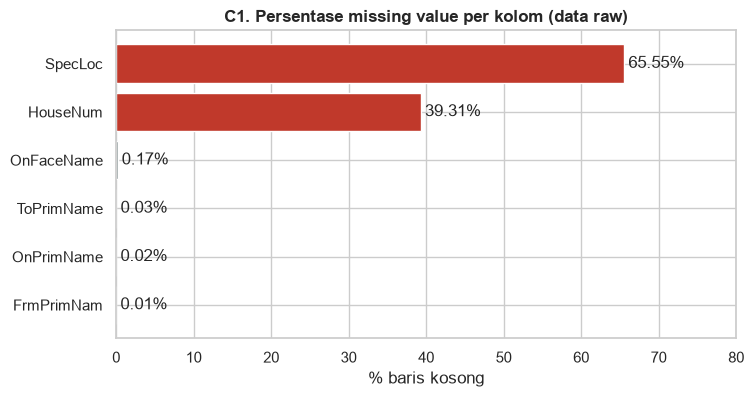

In [7]:
# Viz C1: persentase missing per kolom
m = missing.query("n_missing > 0")["pct_missing"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(m.index, m.values, color=["#c0392b" if v > 30 else "#7f8c8d" for v in m.values])
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in m.values], padding=3)
ax.set_xlabel("% baris kosong")
ax.set_title("C1. Persentase missing value per kolom (data raw)")
ax.set_xlim(0, 80)
savefig("C1_missing_pct_raw")
plt.show()

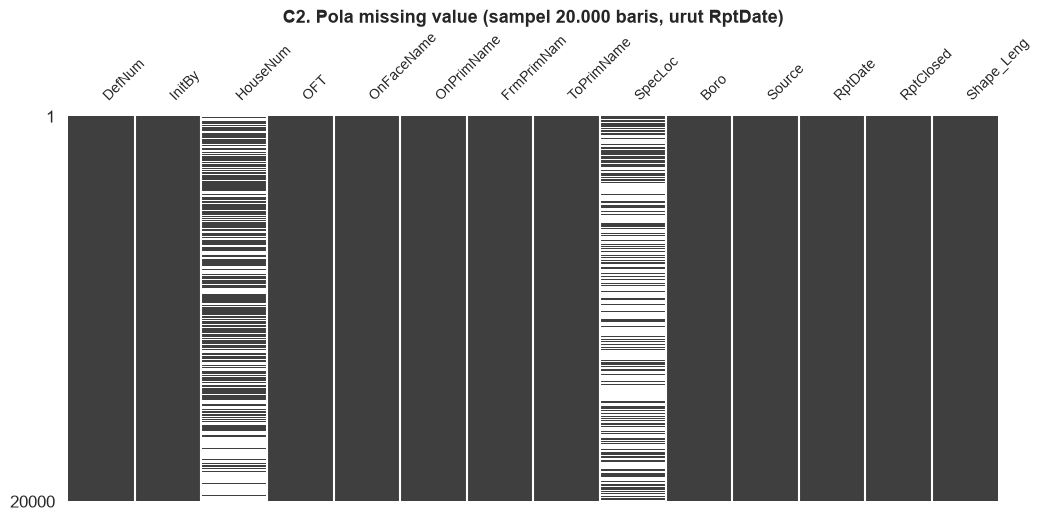

In [8]:
# Viz C2: pola missing (sampel 20.000 baris, urut waktu laporan)
sample = (pothole_raw.drop(columns="the_geom")
          .sample(20_000, random_state=RANDOM_STATE)
          .sort_values("RptDate"))
ax = msno.matrix(sample, figsize=(12, 5), fontsize=10, sparkline=False)
ax.set_title("C2. Pola missing value (sampel 20.000 baris, urut RptDate)", fontsize=13)
savefig("C2_missingno_raw")
plt.show()

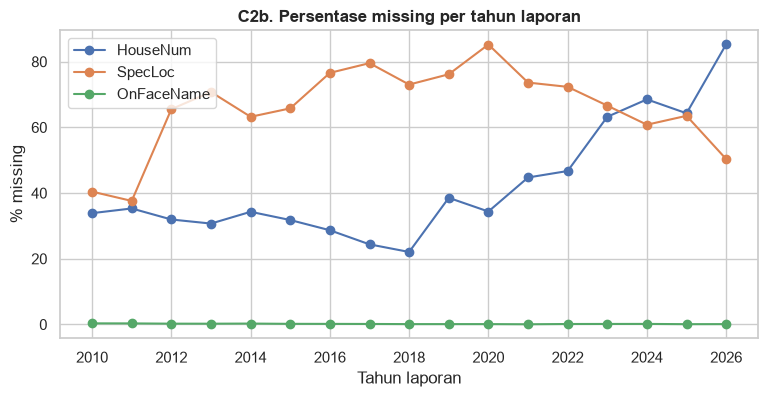

In [9]:
# Apakah missing HouseNum/SpecLoc berubah dari tahun ke tahun? (indikasi MAR, bukan MCAR)
yr = pothole_raw["RptDate"].str[:4].astype(int)
miss_by_year = (pothole_raw[["HouseNum", "SpecLoc", "OnFaceName"]].isna()
                .groupby(yr).mean().mul(100).loc[2010:])

fig, ax = plt.subplots(figsize=(9, 4))
miss_by_year.plot(ax=ax, marker="o")
ax.set_ylabel("% missing"); ax.set_xlabel("Tahun laporan")
ax.set_title("C2b. Persentase missing per tahun laporan")
savefig("C2b_missing_by_year")
plt.show()

In [10]:
issue("pothole", "SpecLoc",  "Teks bebas, sebagian besar kosong", pothole_raw["SpecLoc"].isna().sum(),
      "Jadikan flag has_specloc, lalu drop kolom")
issue("pothole", "HouseNum", "Banyak kosong (lokasi tidak di depan alamat)", pothole_raw["HouseNum"].isna().sum(),
      "Jadikan flag has_housenum, lalu drop kolom")
issue("pothole", "OnFaceName", "Kosong", pothole_raw["OnFaceName"].isna().sum(),
      "Isi dari OnPrimName (redundan), sisanya 'UNKNOWN'")
issue("pothole", "OnPrimName/FrmPrimNam/ToPrimName", "Kosong",
      pothole_raw[["OnPrimName", "FrmPrimNam", "ToPrimName"]].isna().any(axis=1).sum(),
      "Isi 'UNKNOWN' (tidak dipakai sebagai fitur numerik)")

### 2.4 Atribut kategorikal: `Boro`, `InitBy`, `Source`

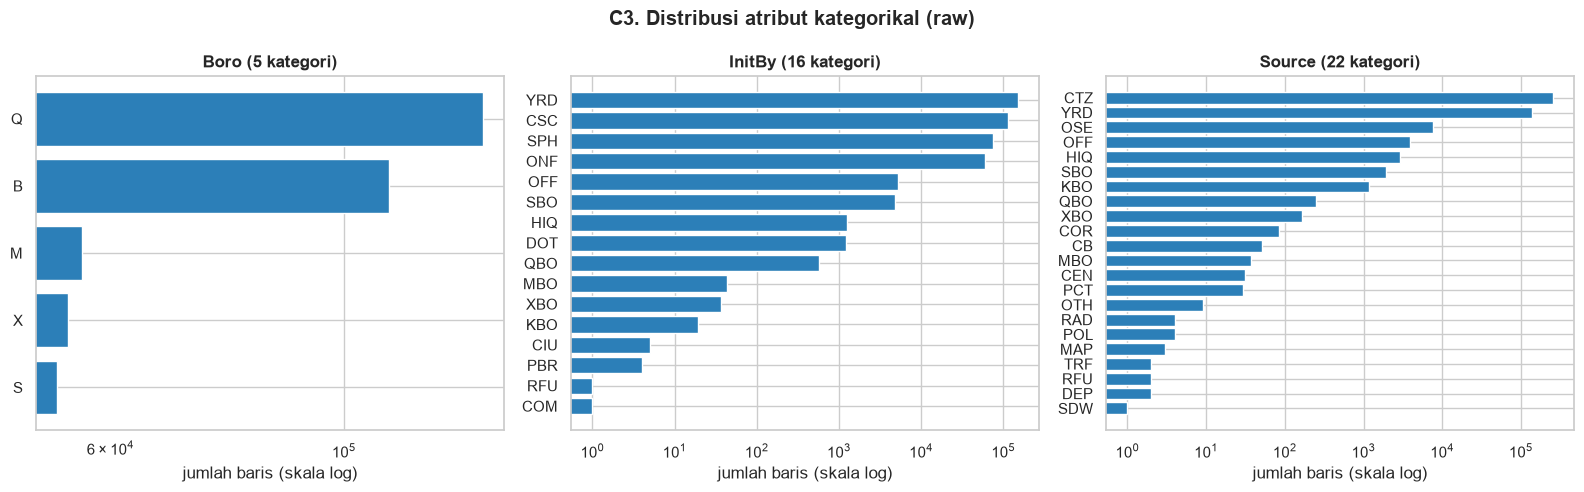

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["Boro", "InitBy", "Source"]):
    vc = pothole_raw[col].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color="#2c7fb8")
    ax.set_xscale("log")
    ax.set_title(f"{col} ({vc.size} kategori)")
    ax.set_xlabel("jumlah baris (skala log)")
fig.suptitle("C3. Distribusi atribut kategorikal (raw)", fontweight="bold")
plt.tight_layout()
savefig("C3_categorical_raw")
plt.show()

In [12]:
rare = {}
for col in ["InitBy", "Source"]:
    share = pothole_raw[col].value_counts(normalize=True)
    rare[col] = share[share < 0.01]
    print(f"{col}: {share.size} kode, {rare[col].size} kode < 1% baris "
          f"(total {rare[col].sum()*100:.2f}% data)")
    print("   kode langka:", ", ".join(rare[col].index))

issue("pothole", "InitBy", "Instansi penangan: banyak kode langka (<1%)",
      pothole_raw["InitBy"].isin(rare["InitBy"].index).sum(),
      "Pertahankan kode besar (YRD, CSC, SPH, ONF), sisanya → OTHER")
issue("pothole", "Source", "Sumber pelapor: banyak kode langka (<1%)",
      pothole_raw["Source"].isin(rare["Source"].index).sum(),
      "Pertahankan CTZ & YRD, sisanya → OTHER")

InitBy: 16 kode, 10 kode < 1% baris (total 0.77% data)
   kode langka: HIQ, DOT, QBO, MBO, XBO, KBO, CIU, PBR, RFU, COM
Source: 22 kode, 19 kode < 1% baris (total 2.58% data)
   kode langka: OFF, HIQ, SBO, KBO, QBO, XBO, COR, CB, MBO, CEN, PCT, OTH, RAD, POL, MAP, TRF, RFU, DEP, SDW


Metadata resmi hanya mendaftar kode untuk `Source`, **tidak untuk `InitBy`**. Dari 16 kode `InitBy`, 9 kebetulan sama dengan kode resmi `Source` (`YRD`, `OFF`, `SBO`, `HIQ`, `QBO`, `MBO`, `XBO`, `KBO`, `RFU` — unit yang sama dipakai untuk dua peran berbeda), sedangkan 7 sisanya (`CSC`, `SPH`, `ONF`, `DOT`, `CIU`, `PBR`, `COM`) **tidak terdokumentasi di mana pun**. Kode-kode ini dipakai apa adanya tanpa ditebak artinya.

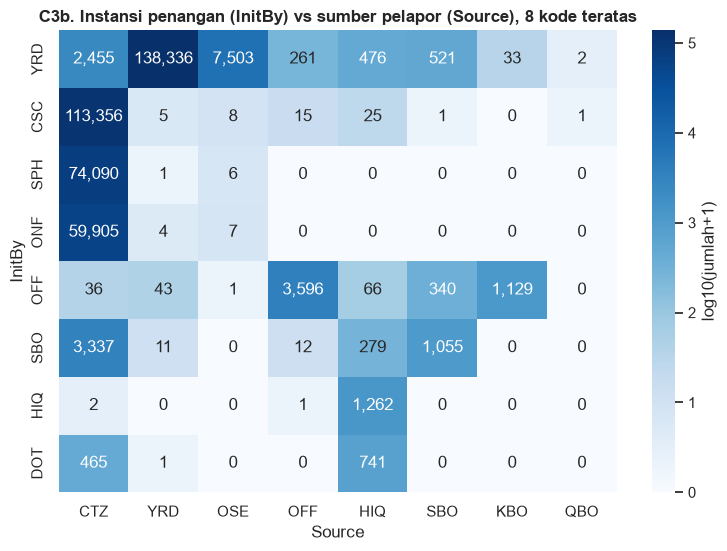

In [13]:
# Apakah instansi penangan (InitBy) bergantung pada sumber pelapor (Source)? Kandidat redundansi / uji chi-square di notebook integrasi
ct = pd.crosstab(pothole_raw["InitBy"], pothole_raw["Source"])
top_i = pothole_raw["InitBy"].value_counts().index[:8]
top_s = pothole_raw["Source"].value_counts().index[:8]
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(np.log10(ct.loc[top_i, top_s] + 1), annot=ct.loc[top_i, top_s], fmt=",d",
            cmap="Blues", cbar_kws={"label": "log10(jumlah+1)"}, ax=ax)
ax.set_title("C3b. Instansi penangan (InitBy) vs sumber pelapor (Source), 8 kode teratas")
savefig("C3b_initby_vs_source")
plt.show()

### 2.5 Atribut tanggal: `RptDate` & `RptClosed`

In [14]:
fmt = "%Y/%m/%d %H:%M:%S"
rpt    = pd.to_datetime(pothole_raw["RptDate"],   format=fmt, errors="coerce")
closed = pd.to_datetime(pothole_raw["RptClosed"], format=fmt, errors="coerce")

print("Gagal parse  RptDate:", rpt.isna().sum(), "| RptClosed:", closed.isna().sum())
print("Rentang RptDate  :", rpt.min().date(), "s/d", rpt.max().date())
print("Rentang RptClosed:", closed.min().date(), "s/d", closed.max().date())
print("Ada komponen jam selain 00:00:00?",
      (~pothole_raw["RptDate"].str.endswith("00:00:00")).sum(),
      (~pothole_raw["RptClosed"].str.endswith("00:00:00")).sum())

Gagal parse  RptDate: 0 | RptClosed: 0
Rentang RptDate  : 1995-05-02 s/d 2026-08-29
Rentang RptClosed: 2010-01-01 s/d 2026-08-30
Ada komponen jam selain 00:00:00? 0 0


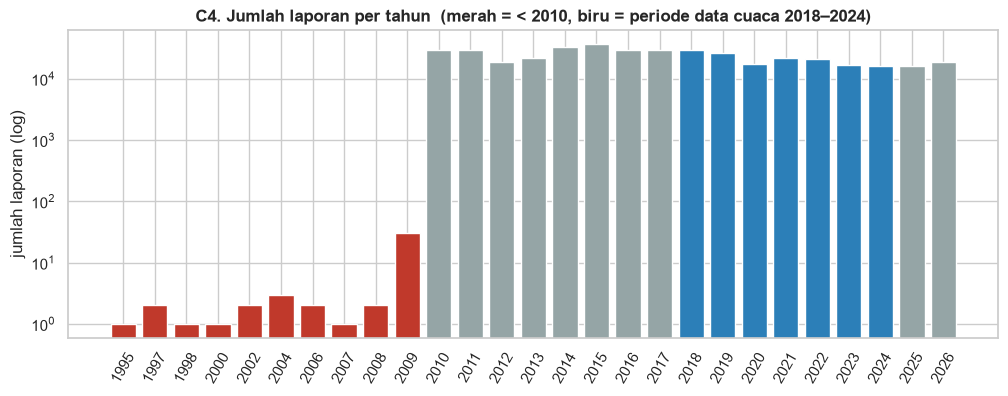

Laporan sebelum 2010: 45 baris, sedangkan 2010 ke atas selalu > 16.000/tahun


In [15]:
per_year = rpt.dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
colors = ["#c0392b" if y < 2010 else ("#2c7fb8" if 2018 <= y <= 2024 else "#95a5a6") for y in per_year.index]
ax.bar(per_year.index.astype(str), per_year.values, color=colors)
ax.set_yscale("log")
ax.set_ylabel("jumlah laporan (log)")
ax.set_title("C4. Jumlah laporan per tahun  (merah = < 2010, biru = periode data cuaca 2018–2024)")
plt.xticks(rotation=60)
savefig("C4_reports_per_year")
plt.show()

pre2010 = (rpt.dt.year < 2010).sum()
print(f"Laporan sebelum 2010: {pre2010} baris, sedangkan 2010 ke atas selalu > 16.000/tahun")
issue("pothole", "RptDate", "Tahun laporan < 2010 (sangat jarang, sisa sistem lama)", pre2010, "Hapus")

In [16]:
repair_days = (closed - rpt).dt.days
print(repair_days.describe(percentiles=[.25, .5, .75, .9, .99]))
print(f"\nSkewness: {repair_days.skew():.1f}")

cats = pd.cut(repair_days, [-np.inf, -1, 0, 7, 30, 365, np.inf],
              labels=["< 0 (tutup sebelum lapor)", "0 (hari yang sama)", "1–7 hari",
                      "8–30 hari", "31–365 hari", "> 365 hari"])
cats.value_counts(sort=False).to_frame("n_rows")

count   410,488.00
mean          4.53
std          29.72
min         -43.00
25%           1.00
50%           1.00
75%           5.00
90%          12.00
99%          33.00
max       6,928.00
dtype: float64

Skewness: 152.0


,n_rows
< 0 (tutup sebelum lapor),593
0 (hari yang sama),37575
1–7 hari,302962
8–30 hari,63966
31–365 hari,5319
> 365 hari,73


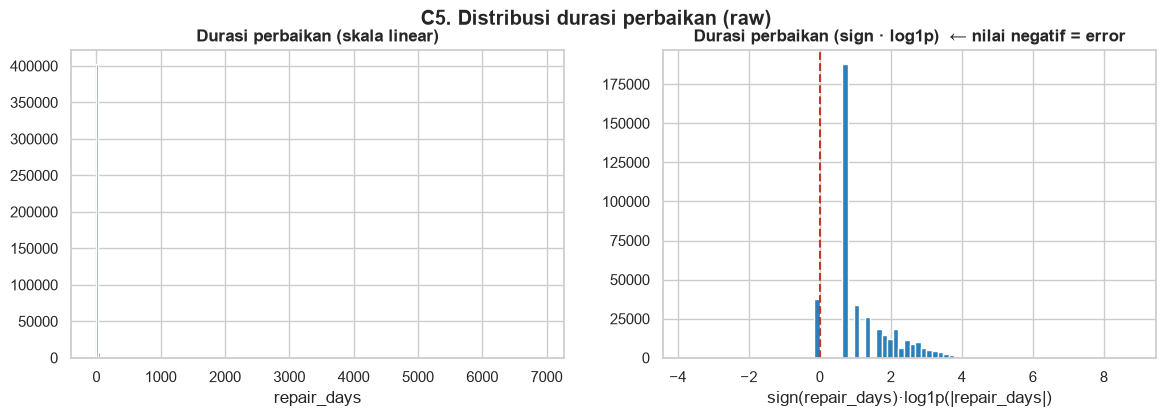

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(repair_days, bins=200, color="#7f8c8d")
axes[0].set_title("Durasi perbaikan (skala linear)")
axes[0].set_xlabel("repair_days")
axes[1].hist(np.sign(repair_days) * np.log1p(repair_days.abs()), bins=80, color="#2c7fb8")
axes[1].axvline(0, color="#c0392b", ls="--")
axes[1].set_title("Durasi perbaikan (sign · log1p)  ← nilai negatif = error")
axes[1].set_xlabel("sign(repair_days)·log1p(|repair_days|)")
fig.suptitle("C5. Distribusi durasi perbaikan (raw)", fontweight="bold")
savefig("C5_repair_days_raw")
plt.show()

In [18]:
print(f"{(repair_days < 0).sum()} work order ditutup SEBELUM dilaporkan (durasi negatif).")

issue("pothole", "RptDate/RptClosed", "Durasi negatif (ditutup sebelum dilaporkan)", (repair_days < 0).sum(), "Hapus (error logis)")
issue("pothole", "RptDate/RptClosed", "Durasi > 365 hari", (repair_days > 365).sum(), "Hapus (work order lupa ditutup)")
issue("pothole", "RptDate/RptClosed", "Distribusi durasi sangat right-skewed", 0,
      "Deteksi outlier pada skala log; bandingkan IQR/Z/MAD/IsolationForest")

593 work order ditutup SEBELUM dilaporkan (durasi negatif).


### 2.6 Atribut numerik: `Shape_Leng`

count   410,488.00
mean        531.08
std         430.23
min           9.82
50%         459.65
99%       1,927.90
99.9%     3,759.17
max     140,472.81
Name: Shape_Leng, dtype: float64


,OnPrimName,Boro,Shape_Leng
380123,BODY OF WATER,X,"140,472.81"
205447,CROSS BAY BOULEVARD,Q,"9,379.80"
217084,CROSS BAY BOULEVARD,Q,"9,379.80"
247579,CROSS BAY BOULEVARD,Q,"9,379.80"
211387,FOREST PARK DRIVE,Q,"8,590.36"


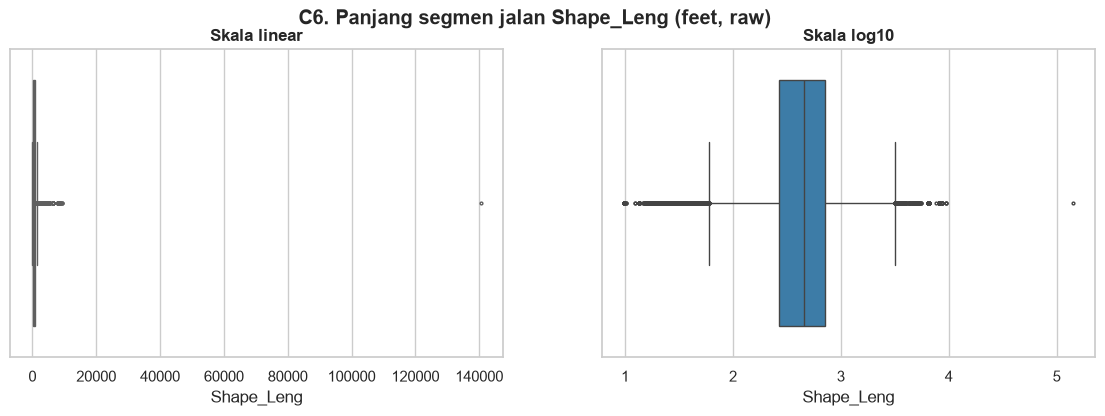

In [19]:
print(pothole_raw["Shape_Leng"].describe(percentiles=[.5, .99, .999]))
display(pothole_raw.nlargest(5, "Shape_Leng")[["OnPrimName", "Boro", "Shape_Leng"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=pothole_raw["Shape_Leng"], ax=axes[0], color="#95a5a6", fliersize=2)
axes[0].set_title("Skala linear")
sns.boxplot(x=np.log10(pothole_raw["Shape_Leng"]), ax=axes[1], color="#2c7fb8", fliersize=2)
axes[1].set_title("Skala log10")
fig.suptitle("C6. Panjang segmen jalan Shape_Leng (feet, raw)", fontweight="bold")
savefig("C6_shape_leng_raw")
plt.show()

water = pothole_raw["OnPrimName"].str.contains("BODY OF WATER", na=False)
issue("pothole", "Shape_Leng", "Segmen 'BODY OF WATER' (bukan jalan), panjang tidak wajar", water.sum(), "Hapus")
issue("pothole", "Shape_Leng", "Segmen > 5.000 ft (parkway/boulevard panjang)",
      (pothole_raw["Shape_Leng"] > 5000).sum(), "Pertahankan, tandai; winsorize untuk PCA")

### 2.7 Konsistensi antar-kolom (informasi yang tersimpan ganda)

`DefNum` punya struktur `D` + kode borough + tahun + nomor urut, misalnya `DB2004041154` = Brooklyn, 2004. Informasi ini bisa dipakai untuk **memvalidasi** kolom `Boro` dan `RptDate`.

DefNum sesuai pola D[BMQSX] + 10 digit: 410488 / 410488


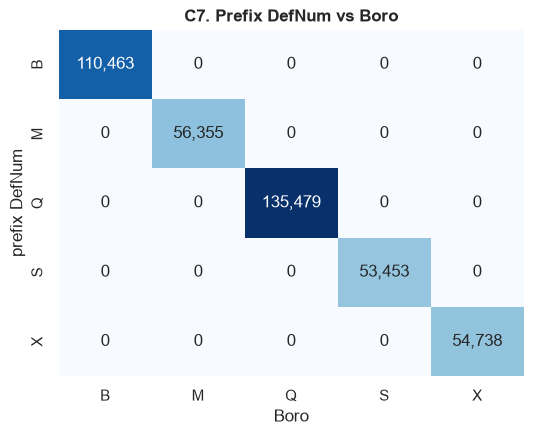

Baris tidak cocok (DefNum vs Boro): 0


In [20]:
defnum_ok = pothole_raw["DefNum"].str.fullmatch(r"D[BMQSX]\d{10}")
print("DefNum sesuai pola D[BMQSX] + 10 digit:", defnum_ok.sum(), "/", len(pothole_raw))

def_boro = pothole_raw["DefNum"].str[1]
def_year = pothole_raw["DefNum"].str[2:6].astype(int)

ct = pd.crosstab(def_boro, pothole_raw["Boro"], rownames=["prefix DefNum"], colnames=["Boro"])
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("C7. Prefix DefNum vs Boro")
savefig("C7_defnum_vs_boro")
plt.show()
print("Baris tidak cocok (DefNum vs Boro):", (def_boro != pothole_raw["Boro"]).sum())

**Temuan:** prefix `DefNum` dan `Boro` **100% konsisten**, artinya `Boro` adalah **atribut redundan** (bisa diturunkan dari `DefNum`). Ini dicatat untuk tahap integrasi/redundansi.

Ada **374 baris** yang tahun di `DefNum`-nya berbeda dari tahun `RptDate`, dan semuanya adalah laporan tanggal **27–31 Desember** dengan DefNum bertahun **berikutnya**. Ini memberi petunjuk bahwa 3 digit setelah tahun adalah **hari ke-n dalam tahun (day-of-year)**, sehingga struktur lengkapnya:

`D` + borough + `YYYY` + `DDD` (hari ke-) + `NNN` (nomor urut) — contoh `DB2004041154` = Brooklyn, hari ke-41 tahun 2004 (10 Feb 2004), urutan 154.

Hipotesis ini diuji di bawah dengan mem-parse tanggal dari DefNum.

Tahun DefNum ≠ tahun RptDate: 374 | semuanya laporan akhir Desember: True
DefNum gagal di-parse sebagai tanggal: 0 | tanggal DefNum < RptDate: 0 | jeda maks: 38 hari


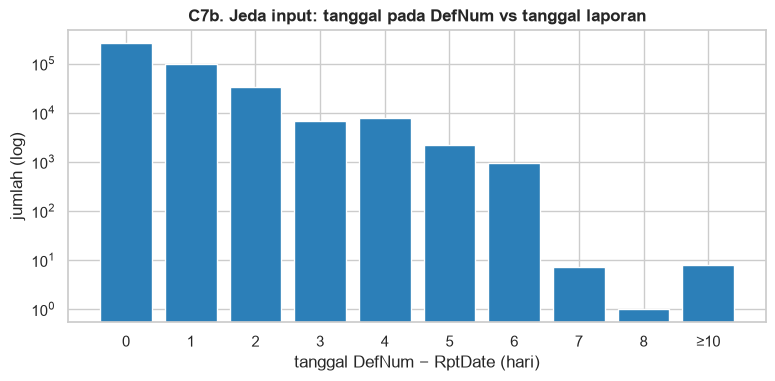

In [21]:
year_mismatch = def_year != rpt.dt.year
def_date  = pd.to_datetime(pothole_raw["DefNum"].str[2:9], format="%Y%j", errors="coerce")
entry_lag = (def_date - rpt).dt.days

print("Tahun DefNum ≠ tahun RptDate:", year_mismatch.sum(),
      "| semuanya laporan akhir Desember:", rpt[year_mismatch].dt.month.eq(12).all())
print("DefNum gagal di-parse sebagai tanggal:", def_date.isna().sum(),
      "| tanggal DefNum < RptDate:", (entry_lag < 0).sum(),
      "| jeda maks:", int(entry_lag.max()), "hari")

fig, ax = plt.subplots(figsize=(9, 3.8))
vc = entry_lag.clip(upper=10).value_counts().sort_index()
ax.bar(vc.index.astype(str).where(vc.index < 10, "≥10"), vc.values, color="#2c7fb8")
ax.set_yscale("log")
ax.set_xlabel("tanggal DefNum − RptDate (hari)"); ax.set_ylabel("jumlah (log)")
ax.set_title("C7b. Jeda input: tanggal pada DefNum vs tanggal laporan")
savefig("C7b_defnum_entry_lag")
plt.show()

issue("pothole", "DefNum/RptDate", "Tahun DefNum ≠ tahun RptDate (laporan 27–31 Des)", year_mismatch.sum(),
      "BUKAN error: DefNum = tanggal input sistem; jeda wajar lintas tahun")
issue("pothole", "DefNum/RptDate", "Jeda input DefNum − RptDate > 7 hari", (entry_lag > 7).sum(),
      "Tandai sebagai anomali administratif (pertahankan)")

**Temuan:** tanggal pada DefNum **tidak pernah lebih awal** dari `RptDate`, dan jedanya 0–6 hari (hanya segelintir > 7 hari). Jadi DefNum mencatat **tanggal input ke sistem**. Ketidakcocokan tahun di atas **bukan error**, melainkan efek pergantian tahun. Ini contoh bahwa tidak semua "inkonsistensi" harus dihapus.

In [22]:
# OnFaceName (singkatan) vs OnPrimName (lengkap): satu nama singkat seharusnya punya satu nama lengkap
face_to_prim = pothole_raw.groupby("OnFaceName")["OnPrimName"].nunique()
print("OnFaceName dengan >1 OnPrimName:", (face_to_prim > 1).sum(), "dari", face_to_prim.size)
print("OnFaceName kosong tapi OnPrimName ada:",
      (pothole_raw["OnFaceName"].isna() & pothole_raw["OnPrimName"].notna()).sum())

issue("pothole", "OnFaceName/OnPrimName", "Nama jalan tersimpan dua kali (singkatan & lengkap)", 0,
      "Redundan: pertahankan OnPrimName, OnFaceName dipakai hanya untuk imputasi")

OnFaceName dengan >1 OnPrimName: 30 dari 6707
OnFaceName kosong tapi OnPrimName ada: 641


### 2.8 Duplikat

In [23]:
dup_exact  = pothole_raw.duplicated().sum()
dup_id     = pothole_raw["DefNum"].duplicated().sum()
dup_logic  = pothole_raw.duplicated(["RptDate", "OFT", "SpecLoc"], keep=False)
dup_logic_n = pothole_raw.duplicated(["RptDate", "OFT", "SpecLoc"]).sum()

print("Duplikat persis          :", dup_exact)
print("Duplikat DefNum          :", dup_id)
print("Duplikat logis (tanggal + segmen + catatan sama):", dup_logic_n,
      f"baris berlebih, dalam {dup_logic.sum():,} baris yang terlibat")

grp = pothole_raw[dup_logic].sort_values(["OFT", "RptDate"])
display(grp[["DefNum", "InitBy", "Source", "OFT", "OnPrimName", "SpecLoc", "RptDate", "RptClosed"]].head(8))

issue("pothole", "(RptDate, OFT, SpecLoc)", "Duplikat logis: lubang yang sama dilaporkan >1 kali di hari yang sama",
      dup_logic_n, "Pertahankan 1 baris per grup (RptClosed paling awal)")

Duplikat persis          : 0
Duplikat DefNum          : 0
Duplikat logis (tanggal + segmen + catatan sama): 8853 baris berlebih, dalam 15,891 baris yang terlibat


,DefNum,InitBy,Source,OFT,OnPrimName,SpecLoc,RptDate,RptClosed
149818,DM2019308015,YRD,OSE,110010100929119190,1 AVENUE,NaN,2019/11/02 00:00:00,2019/11/03 00:00:00
149819,DM2019308016,YRD,OSE,110010100929119190,1 AVENUE,NaN,2019/11/02 00:00:00,2019/11/03 00:00:00
161815,DM2025022002,YRD,YRD,110010117170117190,1 AVENUE,NaN,2025/01/20 00:00:00,2025/01/22 00:00:00
161816,DM2025022003,YRD,YRD,110010117170117190,1 AVENUE,NaN,2025/01/20 00:00:00,2025/01/21 00:00:00
151666,DM2020220009,SPH,CTZ,110010117190117210,1 AVENUE,NaN,2020/08/07 00:00:00,2020/08/09 00:00:00
151667,DM2020220010,CSC,CTZ,110010117190117210,1 AVENUE,NaN,2020/08/07 00:00:00,2020/08/09 00:00:00
156917,DM2023019013,YRD,YRD,110010117710117730,1 AVENUE,NaN,2023/01/18 00:00:00,2023/01/19 00:00:00
156920,DM2023019016,YRD,YRD,110010117710117730,1 AVENUE,NaN,2023/01/18 00:00:00,2023/01/19 00:00:00


### 2.9 Kualitas teks bebas `SpecLoc`

In [24]:
spec = pothole_raw["SpecLoc"].dropna().str.upper().str.strip()
ifo = spec[spec.str.contains(r"^(?:IN FRONT|IFO|I/F/O)", regex=True)]
print("Nilai unik:", spec.nunique(),
      "| variasi penulisan 'in front of':", ifo.nunique(), "bentuk berbeda")
display(spec.value_counts().head(8).to_frame("n"))

# Teks sampah: tanpa huruf vokal / karakter berulang
# (engine string pyarrow tidak mendukung backreference regex, jadi pakai modul re)
no_vowel = spec.str.fullmatch(r"[B-DF-HJ-NP-TV-Z]{6,}")
repeated = spec.map(lambda s: bool(re.search(r"(.)\1{4,}", s)))
junk = spec[no_vowel | repeated]
print("\nContoh teks sampah:", junk.unique()[:10].tolist())

issue("pothole", "SpecLoc", "Teks bebas tidak baku (IFO / I/F/O / IN FRONT OF ...) dan ada teks sampah/karakter berulang", junk.size,
      "Tidak dinormalisasi; hanya dipakai sebagai flag has_specloc")

Nilai unik: 91765 | variasi penulisan 'in front of': 8087 bentuk berbeda


,n
SpecLoc,
POTHOLE,21317
IN FRONT OF ADDRESS,907
MULTIPLE POTHOLES,802
IN FRONT OF,739
IN FRONT OF LOCATION,499
MIDDLE OF THE STREET,467
MIDDLE OF STREET,463
IN THE MIDDLE OF THE STREET,445



Contoh teks sampah: ["OPP 9 DITMAS AVE;PO IN OLD TRENCH;PER INSP'D......", "4'X 2' PATCH UNRAVELLING;311# 1-1-547791574;......", "OLD CUT UNRAVELLING IFO ADDR;INSP'D 3/24/2010.....", 'NEEDS TO BE COMPLETED ``````', 'ASPHALT BROKEN & CRACKED, 12\' X 2\' X 2", P/L     L', 'FILLS WITH WATER  ON JACKSON APLACE CORNER```````', 'LARGEQQQAAAAAAAAAAQQQ', 'PONDING CONDITION,     ASP  11:30 - 1 PM FRI', 'F/O 430 100 STREET                     11209', '......RIGHT LANE OF MAIN ROADWAY.......']


### 2.10 Geometri `the_geom`: validasi lokasi

Tipe geometri: {'MULTILINESTRING': 410488}
Jumlah titik per geometri: {'min': 2.0, '50%': 2.0, 'max': 3512.0}
Titik tengah di luar bounding box NYC: 0


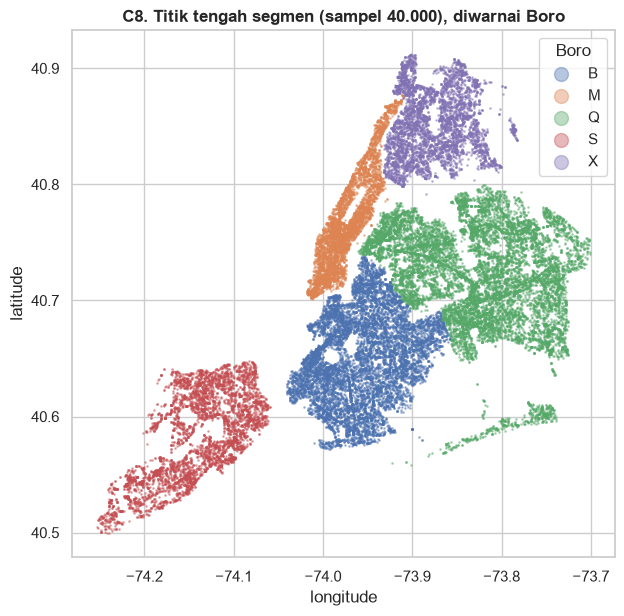

In [25]:
coords = pothole_raw["the_geom"].str.findall(r"(-?\d+\.\d+) (-?\d+\.\d+)")
n_points = coords.str.len()
lon = coords.map(lambda c: np.mean([float(x) for x, _ in c]))
lat = coords.map(lambda c: np.mean([float(y) for _, y in c]))

print("Tipe geometri:", pothole_raw["the_geom"].str.extract(r"^(\w+)")[0].value_counts().to_dict())
print("Jumlah titik per geometri:", n_points.describe()[["min", "50%", "max"]].to_dict())

NYC_BBOX = dict(lat=(40.49, 40.92), lon=(-74.26, -73.70))
outside = ~(lat.between(*NYC_BBOX["lat"]) & lon.between(*NYC_BBOX["lon"]))
print("Titik tengah di luar bounding box NYC:", outside.sum())

fig, ax = plt.subplots(figsize=(7, 7))
samp = pothole_raw.sample(40_000, random_state=RANDOM_STATE).index
for b, g in pothole_raw.loc[samp].groupby("Boro"):
    ax.scatter(lon[g.index], lat[g.index], s=1, alpha=.4, label=b)
ax.legend(markerscale=10, title="Boro")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("C8. Titik tengah segmen (sampel 40.000), diwarnai Boro")
ax.set_aspect(1.3)
savefig("C8_geometry_map")
plt.show()

Semua titik berada di dalam NYC dan warnanya mengelompok rapi per borough, jadi **tidak ada error koordinat**. `the_geom` cukup diringkas menjadi `lon`/`lat` (titik tengah) lalu kolom aslinya dibuang untuk menghemat memori.

## 3. Data Understanding: Cuaca NYC

In [26]:
weather_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_2m_max,"2,557.00",17.20,9.71,-12.70,9.10,17.50,25.70,37.60
temperature_2m_min,"2,557.00",8.51,9.22,-20.50,0.90,8.20,16.60,26.30
precipitation_sum,"2,557.00",3.89,9.11,0.00,0.00,0.10,3.40,187.20
rain_sum,"2,557.00",3.67,8.96,0.00,0.00,0.10,3.00,187.20
snowfall_sum,"2,557.00",0.15,1.20,0.00,0.00,0.00,0.00,27.02


In [27]:
w = weather_raw.copy()
w["time"] = pd.to_datetime(w["time"], format="%Y-%m-%d", errors="coerce")

full = pd.date_range(w["time"].min(), w["time"].max(), freq="D")
checks = pd.Series({
    "tanggal gagal parse":            w["time"].isna().sum(),
    "tanggal duplikat":               w["time"].duplicated().sum(),
    "tanggal hilang (bolong)":        len(full.difference(w["time"])),
    "missing value (semua kolom)":    w.isna().sum().sum(),
    "tmin > tmax":                    (w["temperature_2m_min"] > w["temperature_2m_max"]).sum(),
    "rain > precipitation":           (w["rain_sum"] > w["precipitation_sum"]).sum(),
    "nilai negatif (hujan/salju)":    (w[["precipitation_sum", "rain_sum", "snowfall_sum"]] < 0).sum().sum(),
})
print("Periode:", w["time"].min().date(), "s/d", w["time"].max().date(), f"({len(w)} hari)")
checks.to_frame("jumlah pelanggaran")

Periode: 2018-01-01 s/d 2024-12-31 (2557 hari)


,jumlah pelanggaran
tanggal gagal parse,0
tanggal duplikat,0
tanggal hilang (bolong),0
missing value (semua kolom),0
tmin > tmax,0
rain > precipitation,0
nilai negatif (hujan/salju),0


Data cuaca lolos semua aturan validasi struktural. Meski begitu, **lolos validasi belum tentu nilainya benar**, sehingga nilai ekstremnya tetap dicek.

,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,snowfall_sum
time,,,,,
2022-10-04,12.90,8.40,187.20,187.20,0.00
2021-09-01,23.40,18.50,111.50,111.50,0.00
2023-12-18,15.60,5.90,78.90,78.90,0.00
2021-10-26,17.30,13.90,78.80,78.80,0.00
2023-09-29,17.20,13.20,69.90,69.90,0.00
2021-08-22,23.80,22.50,67.30,67.30,0.00


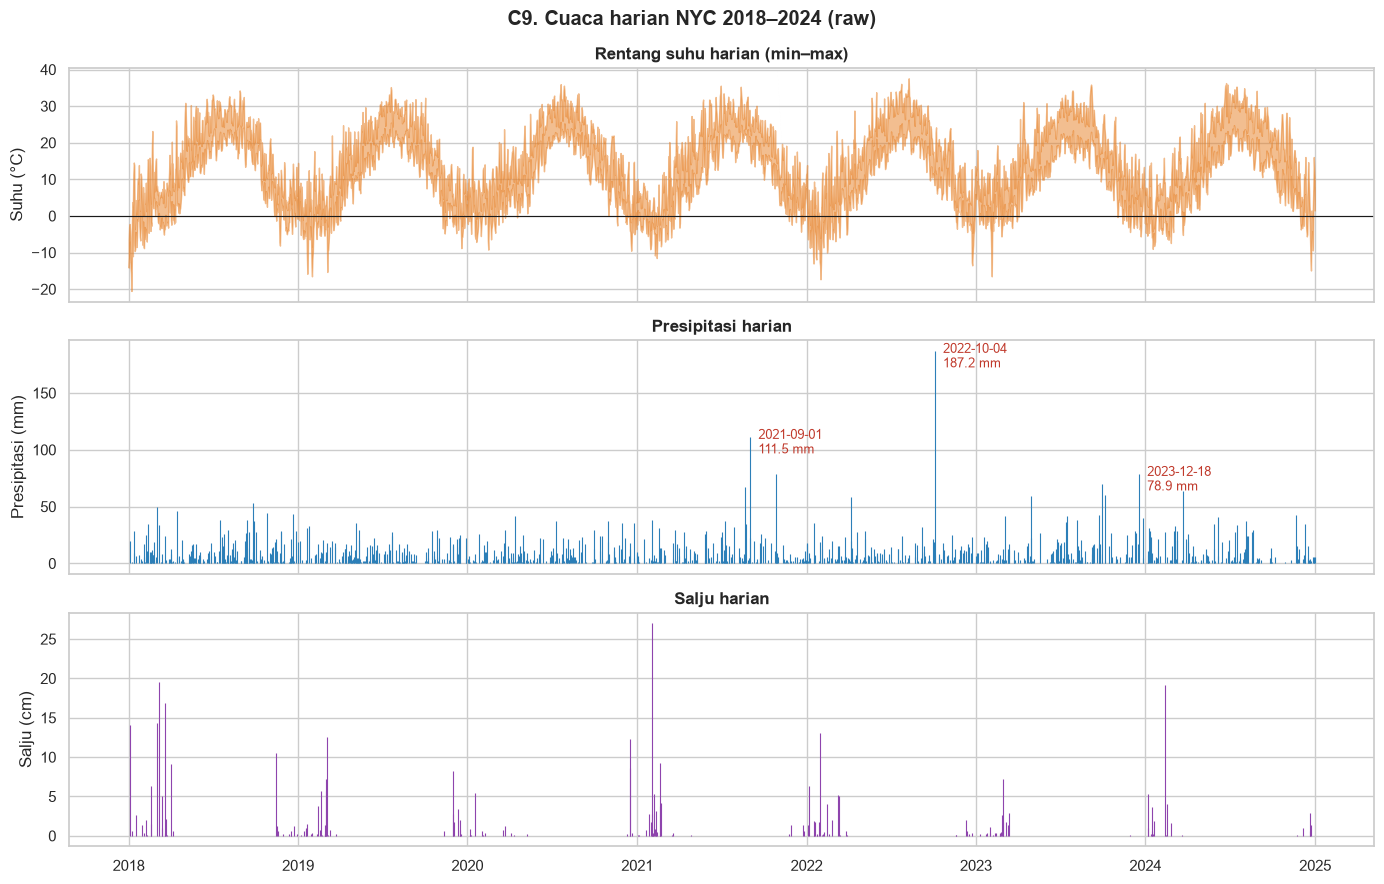

In [28]:
top_precip = w.nlargest(6, "precipitation_sum").set_index("time")
display(top_precip)

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].fill_between(w["time"], w["temperature_2m_min"], w["temperature_2m_max"], color="#e67e22", alpha=.5)
axes[0].axhline(0, color="k", lw=.8)
axes[0].set_ylabel("Suhu (°C)"); axes[0].set_title("Rentang suhu harian (min–max)")

axes[1].vlines(w["time"], 0, w["precipitation_sum"], color="#2c7fb8", lw=0.8)
for t, v in top_precip["precipitation_sum"].head(3).items():
    axes[1].annotate(f"{t.date()}\n{v} mm", (t, v), textcoords="offset points", xytext=(6, -12),
                     fontsize=9, color="#c0392b")
axes[1].set_ylabel("Presipitasi (mm)"); axes[1].set_title("Presipitasi harian")

axes[2].vlines(w["time"], 0, w["snowfall_sum"], color="#8e44ad", lw=0.8)
axes[2].set_ylabel("Salju (cm)"); axes[2].set_title("Salju harian")
fig.suptitle("C9. Cuaca harian NYC 2018–2024 (raw)", fontweight="bold")
plt.tight_layout()
savefig("C9_weather_timeseries_raw")
plt.show()

**Temuan penting:** presipitasi tertinggi (**187,2 mm pada 2022-10-04**) lebih besar dari Badai Ida (2021-09-01, 111,5 mm) yang merupakan rekor banjir NYC, padahal tidak ada catatan kejadian ekstrem sebesar itu pada tanggal tersebut. Sementara itu banjir 29 Sep 2023 hanya tercatat 69,9 mm. Nilai ini **patut dicurigai sebagai error data model/reanalysis** (Open-Meteo adalah data model, bukan stasiun).

Rencana: verifikasi dengan data stasiun NOAA Central Park (GHCN-Daily `USW00094728`) untuk tanggal yang sama. Jika terbukti tidak wajar, nilainya diganti `NaN` lalu diimputasi di tahap cleaning. Keputusan ini dibahas di laporan sebagai contoh **outlier yang merupakan error**, kebalikan dari Ida yang merupakan **outlier nyata**.

% hari bernilai 0:
precipitation_sum   46.30
rain_sum            48.30
snowfall_sum        93.80
dtype: float64

Hari dengan precipitation ≠ rain (ada salju): 158
Hari beku-cair (tmin < 0 < tmax): 492


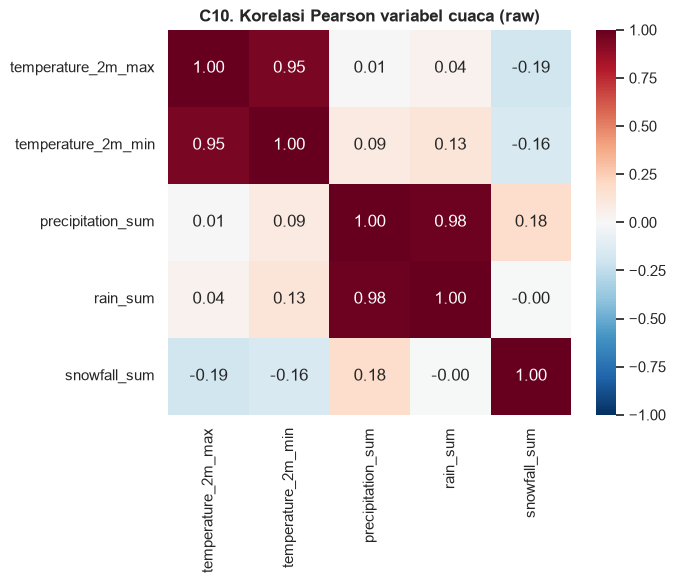

In [29]:
zero_share = (w[["precipitation_sum", "rain_sum", "snowfall_sum"]] == 0).mean().mul(100).round(1)
print("% hari bernilai 0:"); print(zero_share)
print("\nHari dengan precipitation ≠ rain (ada salju):", (w["precipitation_sum"] != w["rain_sum"]).sum())
print("Hari beku-cair (tmin < 0 < tmax):",
      ((w["temperature_2m_min"] < 0) & (w["temperature_2m_max"] > 0)).sum())

corr = w.drop(columns="time").corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("C10. Korelasi Pearson variabel cuaca (raw)")
savefig("C10_weather_corr_raw")
plt.show()

In [30]:
issue("weather", "precipitation_sum/rain_sum", "Nilai 187,2 mm pada 2022-10-04 mencurigakan (> Badai Ida)", 1,
      "Verifikasi dgn NOAA Central Park; jika tidak wajar → NaN lalu interpolasi")
issue("weather", "rain_sum", "Hampir identik dengan precipitation_sum (berbeda hanya saat salju)",
      (w["precipitation_sum"] != w["rain_sum"]).sum(), "Kandidat atribut redundan (tahap integrasi)")
issue("weather", "temperature_2m_max/min", "Korelasi sangat tinggi antar suhu", 0,
      "Kandidat redundan: ganti dengan temp_mean + temp_range (tahap integrasi)")
issue("weather", "snowfall_sum", "Zero-inflated (mayoritas 0)", (w["snowfall_sum"] == 0).sum(),
      "Buat fitur biner/rolling; log1p sebelum PCA")
issue("weather", "time", "Periode hanya 2018–2024, sedangkan pothole 1995–2026", 0,
      "Filter data gabungan ke 2018-01-01 s/d 2024-12-31")

## 4. Ringkasan Masalah Kualitas Data (Issue Register)

Tabel ini menjadi **daftar kerja** untuk langkah cleaning berikutnya dan disimpan ke `output/data_quality_issues.csv`.

In [31]:
issues_df = pd.DataFrame(issues)
issues_df.index = issues_df.index + 1
issues_df.to_csv(OUT_DIR / "data_quality_issues.csv", index_label="no")
issues_df

,dataset,column,problem,n_rows,planned_action
1,pothole,SpecLoc,"Teks bebas, sebagian besar kosong",269062,"Jadikan flag has_specloc, lalu drop kolom"
2,pothole,HouseNum,Banyak kosong (lokasi tidak di depan alamat),161356,"Jadikan flag has_housenum, lalu drop kolom"
3,pothole,OnFaceName,Kosong,718,"Isi dari OnPrimName (redundan), sisanya 'UNKNOWN'"
4,pothole,OnPrimName/FrmPrimNam/ToPrimName,Kosong,206,Isi 'UNKNOWN' (tidak dipakai sebagai fitur num...
5,pothole,InitBy,Instansi penangan: banyak kode langka (<1%),3165,"Pertahankan kode besar (YRD, CSC, SPH, ONF), s..."
6,pothole,Source,Sumber pelapor: banyak kode langka (<1%),10596,"Pertahankan CTZ & YRD, sisanya → OTHER"
7,pothole,RptDate,"Tahun laporan < 2010 (sangat jarang, sisa sist...",45,Hapus
8,pothole,RptDate/RptClosed,Durasi negatif (ditutup sebelum dilaporkan),593,Hapus (error logis)
9,pothole,RptDate/RptClosed,Durasi > 365 hari,73,Hapus (work order lupa ditutup)
10,pothole,RptDate/RptClosed,Distribusi durasi sangat right-skewed,0,Deteksi outlier pada skala log; bandingkan IQR...


---
# BAGIAN B: DATA CLEANING

Semua langkah di bawah memakai **salinan** data raw (`df`). Setiap langkah yang mengubah jumlah baris/kolom dicatat oleh `log()` untuk funnel chart di akhir.

Level data tetap **1 baris = 1 work order**. Agregasi per hari dilakukan di `data_integration.ipynb`.

Grafik hasil cleaning diberi awalan **D** (C = profiling data raw).

## 5. Perbaikan Struktur & Tipe Data (plan 3.3)

In [32]:
df = pothole_raw.copy()
dtype_before = df.dtypes.astype(str)

# 1) Kolom teks: buang spasi di tepi, string kosong -> NaN
text_cols = [c for c in df.columns if c != "Shape_Leng"]
na_before = df[text_cols].isna().sum().sum()
for c in text_cols:
    df[c] = df[c].str.strip().replace({"": np.nan})
print("NaN baru dari string kosong/spasi:", df[text_cols].isna().sum().sum() - na_before)

# 2) Tanggal: string 'YYYY/MM/DD 00:00:00' -> datetime (komponen jam selalu 00:00:00, jadi di-normalize)
fmt = "%Y/%m/%d %H:%M:%S"
for c in ["RptDate", "RptClosed"]:
    df[c] = pd.to_datetime(df[c], format=fmt, errors="coerce").dt.normalize()
print("Gagal parse tanggal:", df[["RptDate", "RptClosed"]].isna().sum().to_dict())

# 3) Numerik
df["Shape_Leng"] = pd.to_numeric(df["Shape_Leng"], errors="coerce")

# 4) Kategori dengan sedikit nilai unik -> category (hemat memori)
for c in ["Boro", "InitBy", "Source"]:
    df[c] = df[c].astype("category")

df = df.dropna(subset=["RptDate", "RptClosed"])
log("3.3 tipe data", df)

pd.DataFrame({"dtype_raw": dtype_before, "dtype_clean": df.dtypes.astype(str)})

NaN baru dari string kosong/spasi: 0


Gagal parse tanggal: {'RptDate': 0, 'RptClosed': 0}
[3.3 tipe data] rows=410,488 cols=15


,dtype_raw,dtype_clean
the_geom,str,str
DefNum,string,string
InitBy,str,category
HouseNum,string,string
OFT,string,string
OnFaceName,str,str
OnPrimName,str,str
FrmPrimNam,str,str
ToPrimName,str,str
SpecLoc,str,str


## 6. Validasi Konsistensi & Imputasi Berbasis Redundansi (plan 3.4)

### 6.1 Struktur `OFT` = 3 kode jalan
Metadata resmi NYC DOT (lihat sitasi di bagian 0) mendefinisikan `OFT` sebagai kode segmen blok **On–From–To**, "a six-byte code consisting of borough and five digit street code". Digit borough di sini memakai **kode DCP** (1=Manhattan, 2=Bronx, 3=Brooklyn, 4=Queens, 5=Staten Island) — berbeda dari huruf `Boro` (`B/M/Q/S/X`). Pemetaan digit ke huruf borough dan pemisahan 18 digit `OFT` menjadi 3 segmen 6-digit (On/From/To) diverifikasi langsung dari data di bawah.

Contoh: `373480377030377030` → On `373480` (Rockaway Pkwy), From `377030` (Belt Pkwy), To `377030` (Belt Pkwy).

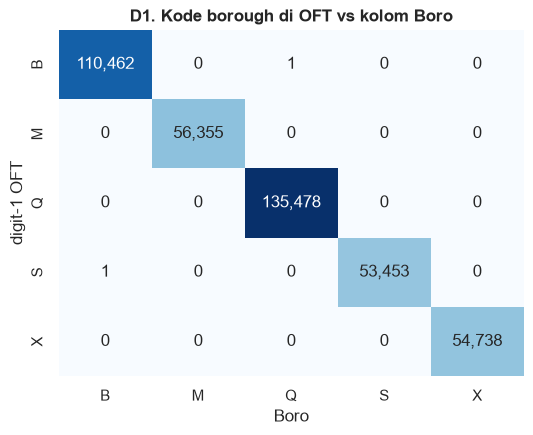

Konflik OFT vs Boro: 2


,DefNum,Boro,OFT,OnPrimName,FrmPrimNam,ToPrimName
91186,DB2022193019,B,524037518510570398,COMMERCE STREET,BEND,NADAL PLACE
172638,DQ2010165005,Q,360530343040375760,METROPOLITAN AVENUE,GARDNER AVENUE,SCOTT AVENUE


In [33]:
df["oft_on"], df["oft_from"], df["oft_to"] = df["OFT"].str[0:6], df["OFT"].str[6:12], df["OFT"].str[12:18]

BORO_DCP = {"1": "M", "2": "X", "3": "B", "4": "Q", "5": "S"}
oft_boro = df["oft_on"].str[0].map(BORO_DCP)

ct = pd.crosstab(oft_boro, df["Boro"], rownames=["digit-1 OFT"], colnames=["Boro"])
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("D1. Kode borough di OFT vs kolom Boro")
savefig("D1_oft_vs_boro")
plt.show()

df["boro_conflict"] = (oft_boro != df["Boro"].astype(str))
print("Konflik OFT vs Boro:", df["boro_conflict"].sum())
display(df.loc[df["boro_conflict"], ["DefNum", "Boro", "OFT", "OnPrimName", "FrmPrimNam", "ToPrimName"]])

Hanya 2 baris yang konflik, yaitu segmen di **perbatasan borough** (jalan utamanya milik borough tetangga). `Boro` tetap dipakai karena **2 dari 3 sumber sepakat** (`Boro` = prefix `DefNum`). Baris ini tidak dihapus, hanya diberi flag `boro_conflict`.

### 6.2 Kamus kode jalan → nama jalan (imputasi deterministik)
Jika setiap kode jalan 6 digit selalu dipasangkan dengan satu nama jalan yang sama, maka nama jalan yang kosong bisa **diisi dari kodenya**. Ini bukan tebakan statistik, melainkan pemanfaatan atribut redundan.

In [34]:
NAME_PAIRS = [("oft_on", "OnPrimName"), ("oft_from", "FrmPrimNam"), ("oft_to", "ToPrimName")]
pairs = pd.concat([df[[c, n]].set_axis(["code", "name"], axis=1) for c, n in NAME_PAIRS]).dropna()

names_per_code = pairs.groupby("code")["name"].nunique()
print(f"Kode jalan unik: {names_per_code.size:,} | kode dengan >1 nama: {(names_per_code > 1).sum()}")

street_dict = pairs.drop_duplicates("code").set_index("code")["name"]

Kode jalan unik: 10,707 | kode dengan >1 nama: 0


,raw,setelah imputasi\nredundansi,setelah 'UNKNOWN'
OnFaceName,718,123,0
OnPrimName,77,77,0
FrmPrimNam,30,30,0
ToPrimName,106,106,0


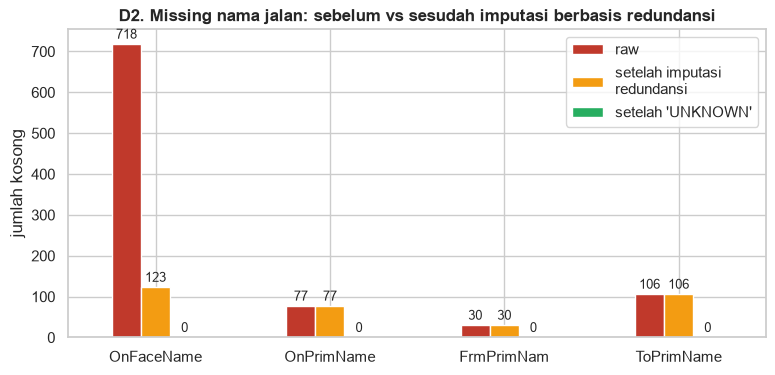

In [35]:
name_cols = ["OnFaceName", "OnPrimName", "FrmPrimNam", "ToPrimName"]
miss_steps = {"raw": df[name_cols].isna().sum()}

# 1) Nama primer diisi dari kamus kode jalan
for c, n in NAME_PAIRS:
    df[n] = df[n].fillna(df[c].map(street_dict))

# 2) OnFaceName (singkatan) diisi dari singkatan yang paling sering dipakai untuk OnPrimName yang sama
face_dict = (df.dropna(subset=["OnFaceName", "OnPrimName"])
               .groupby("OnPrimName")["OnFaceName"].agg(lambda s: s.value_counts().index[0]))
df["OnFaceName"] = df["OnFaceName"].fillna(df["OnPrimName"].map(face_dict))
miss_steps["setelah imputasi\nredundansi"] = df[name_cols].isna().sum()

# 3) Sisa yang benar-benar tidak bisa ditelusuri -> 'UNKNOWN'
df[name_cols] = df[name_cols].fillna("UNKNOWN")
miss_steps["setelah 'UNKNOWN'"] = df[name_cols].isna().sum()

miss_steps = pd.DataFrame(miss_steps)
display(miss_steps)

ax = miss_steps.plot.bar(figsize=(9, 4), color=["#c0392b", "#f39c12", "#27ae60"], rot=0)
for cont in ax.containers:
    ax.bar_label(cont, padding=2, fontsize=9)
ax.set_ylabel("jumlah kosong")
ax.set_title("D2. Missing nama jalan: sebelum vs sesudah imputasi berbasis redundansi")
savefig("D2_street_name_imputation")
plt.show()

**Hasil:**
- `OnFaceName` berhasil diisi dari 718 menjadi 123 baris kosong, karena singkatannya bisa diturunkan dari `OnPrimName`.
- Nama primer yang kosong (`OnPrimName` 77, `FrmPrimNam` 30, `ToPrimName` 106) **tidak bisa diisi**, karena kode jalannya (mis. `467656`) **tidak pernah memiliki nama di baris mana pun**.

Jadi kekosongan ini **bukan acak**. Kemungkinan besar kode tersebut adalah segmen tanpa nama resmi di kamus jalan DOT (missing yang bersifat struktural / MNAR). Menebak nama justru akan menambah error, sehingga nilainya diisi `"UNKNOWN"`. Barisnya tetap dipertahankan karena tanggal, lokasi, dan durasinya valid.

### 6.3 Jeda input `DefNum` (hasil temuan profiling 2.7)

In [36]:
df["entry_lag"] = (pd.to_datetime(df["DefNum"].str[2:9], format="%Y%j") - df["RptDate"]).dt.days
df["entry_lag_anomaly"] = df["entry_lag"] > 7
print("Jeda input > 7 hari (diberi flag, tidak dihapus):", df["entry_lag_anomaly"].sum())

Jeda input > 7 hari (diberi flag, tidak dihapus): 9


## 7. Missing Value (plan 3.5)

| Kolom | Keputusan | Alasan |
|---|---|---|
| `SpecLoc` (65,5% kosong) | Jadi flag `has_specloc`, kolom asli dibuang **setelah** deteksi duplikat | Teks bebas maks. 50 karakter, tidak dipakai sebagai fitur numerik, tetapi masih dibutuhkan sebagai kunci duplikat |
| `HouseNum` (39,3% kosong) | Jadi flag `has_housenum`, kolom asli dibuang | Kosong ≠ error: laporan memakai segmen blok, bukan alamat persis |
| Nama jalan | Sudah diimputasi di 6.2 | Redundansi dengan `OFT` |
| Tanggal | Tidak ada yang kosong | - |

In [37]:
df["has_specloc"]  = df["SpecLoc"].notna()
df["has_housenum"] = df["HouseNum"].notna()
df[["has_specloc", "has_housenum"]].mean().mul(100).round(2).rename("% True").to_frame()

,% True
has_specloc,34.45
has_housenum,60.69


## 8. Duplikat (plan 3.6)

In [38]:
print("Duplikat persis :", df.drop(columns=["the_geom"]).duplicated().sum())
print("Duplikat DefNum :", df["DefNum"].duplicated().sum())

DUP_KEY = ["RptDate", "OFT", "SpecLoc"]
dup_all   = df.duplicated(DUP_KEY, keep=False)
dup_extra = df.duplicated(DUP_KEY)
print(f"Duplikat logis {DUP_KEY}: {dup_extra.sum():,} baris berlebih (dalam {dup_all.sum():,} baris terlibat)")

# Contoh 3 grup duplikat
ex_keys = df.loc[dup_extra, DUP_KEY].drop_duplicates().head(3)
display(df.merge(ex_keys, on=DUP_KEY)[["DefNum", "InitBy", "Source", "OnPrimName", "SpecLoc", "RptDate", "RptClosed"]])

Duplikat persis : 0


Duplikat DefNum : 0


Duplikat logis ['RptDate', 'OFT', 'SpecLoc']: 8,853 baris berlebih (dalam 15,891 baris terlibat)


,DefNum,InitBy,Source,OnPrimName,SpecLoc,RptDate,RptClosed
0,DB2010005039,CSC,CTZ,METROPOLITAN AVENUE,NaN,2010-01-03,2010-01-04
1,DB2010005040,CSC,CTZ,METROPOLITAN AVENUE,NaN,2010-01-03,2010-01-04
2,DB2010005041,CSC,CTZ,METROPOLITAN AVENUE,NaN,2010-01-03,2010-01-04
3,DB2010005043,CSC,CTZ,METROPOLITAN AVENUE,NaN,2010-01-03,2010-01-04
4,DB2010011014,CSC,CTZ,DEKALB AVENUE,NaN,2010-01-07,2010-01-08
5,DB2010011015,CSC,CTZ,DEKALB AVENUE,NaN,2010-01-07,2010-01-08


Satu lubang di segmen yang sama, di hari yang sama, dengan catatan lokasi yang sama, tetapi punya beberapa `DefNum`. Artinya lubang yang sama **dilaporkan lebih dari sekali**. Kalau dibiarkan, jumlah laporan per hari akan terhitung berlebih.

Yang dipertahankan adalah work order yang **ditutup paling awal**, karena itu kapan lubang benar-benar diperbaiki.

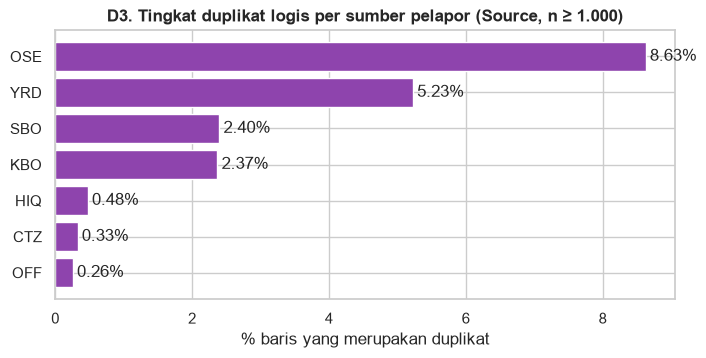

[3.6 hapus duplikat logis] rows=401,635 cols=23


In [39]:
# Sumber pelapor mana yang paling sering menghasilkan duplikat?
dup_rate = (dup_extra.groupby(df["Source"], observed=True).agg(["mean", "size"])
            .query("size >= 1000").sort_values("mean"))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(dup_rate.index.astype(str), dup_rate["mean"] * 100, color="#8e44ad")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set_xlabel("% baris yang merupakan duplikat")
ax.set_title("D3. Tingkat duplikat logis per sumber pelapor (Source, n ≥ 1.000)")
savefig("D3_duplicate_rate_by_source")
plt.show()

df = (df.sort_values(DUP_KEY + ["RptClosed"])
        .drop_duplicates(DUP_KEY, keep="first")
        .sort_index())
log("3.6 hapus duplikat logis", df)

## 9. Feature Engineering & Seleksi Kolom (plan 3.7)

In [40]:
# Durasi perbaikan
df["repair_days"] = (df["RptClosed"] - df["RptDate"]).dt.days

# Titik tengah geometri segmen jalan
coords = df["the_geom"].str.findall(r"(-?\d+\.\d+) (-?\d+\.\d+)")
df["lon"] = coords.map(lambda c: np.mean([float(x) for x, _ in c]))
df["lat"] = coords.map(lambda c: np.mean([float(y) for _, y in c]))
del coords

# Pengelompokan kode kategorikal: kode dengan porsi >= 5% dipertahankan, sisanya OTHER
def group_rare(s, min_share=0.05):
    share = s.value_counts(normalize=True)
    keep = share[share >= min_share].index
    return s.astype(str).where(s.isin(keep), "OTHER").astype("category")

df["InitBy_group"] = group_rare(df["InitBy"])   # instansi yang menangani
df["Source_group"] = group_rare(df["Source"])   # sumber pelapor (CTZ = Citizen)

for c in ["InitBy_group", "Source_group"]:
    print(c, df[c].value_counts(normalize=True).mul(100).round(2).to_dict())

# Atribut waktu
df["report_year"]  = df["RptDate"].dt.year
df["report_month"] = df["RptDate"].dt.month
df["report_dow"]   = df["RptDate"].dt.dayofweek   # 0 = Senin

InitBy_group {'YRD': 35.37, 'CSC': 28.06, 'SPH': 18.42, 'ONF': 14.9, 'OTHER': 3.24}
Source_group {'CTZ': 62.94, 'YRD': 32.73, 'OTHER': 4.33}


In [41]:
DROP_COLS = {
    "the_geom":   "sudah diringkas jadi lon/lat",
    "SpecLoc":    "teks bebas, diganti flag has_specloc",
    "HouseNum":   "diganti flag has_housenum",
    "OnFaceName": "redundan dengan OnPrimName (singkatan)",
    "oft_on":     "kolom bantu (tetap ada di OFT)",
    "oft_from":   "kolom bantu (tetap ada di OFT)",
    "oft_to":     "kolom bantu (tetap ada di OFT)",
}
df = df.drop(columns=list(DROP_COLS))
log("3.7 feature engineering & drop kolom", df)
display(pd.Series(DROP_COLS, name="alasan drop").to_frame())
print("Memori sekarang: {:.1f} MB".format(df.memory_usage(deep=True).sum() / 1e6))

[3.7 feature engineering & drop kolom] rows=401,635 cols=24


,alasan drop
the_geom,sudah diringkas jadi lon/lat
SpecLoc,"teks bebas, diganti flag has_specloc"
HouseNum,diganti flag has_housenum
OnFaceName,redundan dengan OnPrimName (singkatan)
oft_on,kolom bantu (tetap ada di OFT)
oft_from,kolom bantu (tetap ada di OFT)
oft_to,kolom bantu (tetap ada di OFT)


Memori sekarang: 77.8 MB


## 10. Deteksi & Penanganan Outlier (plan 3.8)

### 10.1 Outlier logis (rule-based): error data, dihapus

In [42]:
TODAY = pd.Timestamp("today").normalize()
NYC_BBOX = dict(lat=(40.49, 40.92), lon=(-74.26, -73.70))

RULES = {
    "repair_days < 0 (ditutup sebelum dilaporkan)": lambda d: d["repair_days"] < 0,
    "RptDate < 2010 (sisa sistem lama)":            lambda d: d["RptDate"] < "2010-01-01",
    "Tanggal di masa depan":                        lambda d: (d["RptDate"] > TODAY) | (d["RptClosed"] > TODAY),
    "Koordinat di luar NYC":                        lambda d: ~(d["lat"].between(*NYC_BBOX["lat"]) & d["lon"].between(*NYC_BBOX["lon"])),
    "Shape_Leng <= 0":                              lambda d: d["Shape_Leng"] <= 0,
    "Segmen 'BODY OF WATER' (bukan jalan)":         lambda d: d["OnPrimName"].str.contains("BODY OF WATER", na=False),
}

rule_result = []
for name, rule in RULES.items():
    mask = rule(df)
    rule_result.append({"aturan": name, "baris_dihapus": int(mask.sum())})
    df = df[~mask]
    log(f"3.8a {name}", df)

pd.DataFrame(rule_result)

[3.8a repair_days < 0 (ditutup sebelum dilaporkan)] rows=401,061 cols=24
[3.8a RptDate < 2010 (sisa sistem lama)] rows=401,016 cols=24


[3.8a Tanggal di masa depan] rows=401,016 cols=24
[3.8a Koordinat di luar NYC] rows=401,016 cols=24
[3.8a Shape_Leng <= 0] rows=401,016 cols=24


[3.8a Segmen 'BODY OF WATER' (bukan jalan)] rows=401,013 cols=24


,aturan,baris_dihapus
0,repair_days < 0 (ditutup sebelum dilaporkan),574
1,RptDate < 2010 (sisa sistem lama),45
2,Tanggal di masa depan,0
3,Koordinat di luar NYC,0
4,Shape_Leng <= 0,0
5,Segmen 'BODY OF WATER' (bukan jalan),3


### 10.2 Outlier statistik: perbandingan metode

Diterapkan pada `repair_days` (durasi perbaikan) dan `Shape_Leng` (panjang segmen). Keduanya **sangat right-skewed**, sehingga asumsi normal pada Z-score dilanggar. Perbandingan ini menunjukkan dampak pemilihan metode.

In [43]:
from sklearn.ensemble import IsolationForest

def flag_iqr(x, k=1.5):
    q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    return (x < q1 - k * i) | (x > q3 + k * i), q3 + k * i

def flag_z(x, t=3):
    return ((x - x.mean()) / x.std()).abs() > t, x.mean() + t * x.std()

def flag_mad(x, t=3.5):
    med = x.median(); mad = (x - med).abs().median()
    if mad == 0:                                   # fallback bila > 50% nilai sama dengan median
        mad = (x - med).abs().mean() / 1.2533
    return (0.6745 * (x - med) / mad).abs() > t, med + t * mad / 0.6745

def flag_log_iqr(x, k=1.5):
    m, upper = flag_iqr(np.log1p(x), k)
    return m, np.expm1(upper)

METHODS = {"IQR": flag_iqr, "Z-score": flag_z, "Modified Z (MAD)": flag_mad, "Log-IQR": flag_log_iqr}

flags, rows = {}, []
for col in ["repair_days", "Shape_Leng"]:
    x = df[col].astype(float)
    print(f"{col}: skewness = {x.skew():.1f}")
    for mname, fn in METHODS.items():
        m, upper = fn(x)
        flags[(col, mname)] = m
        rows.append({"kolom": col, "metode": mname, "batas_atas": round(upper, 1),
                     "n_outlier": int(m.sum()), "% data": round(m.mean() * 100, 2)})

# Isolation Forest (multivariat)
X_if = np.column_stack([np.log1p(df["repair_days"]), np.log(df["Shape_Leng"]), df["lat"], df["lon"]])
iso = IsolationForest(contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1).fit(X_if)
flags[("multivariat", "Isolation Forest")] = pd.Series(iso.predict(X_if) == -1, index=df.index)
m = flags[("multivariat", "Isolation Forest")]
rows.append({"kolom": "multivariat", "metode": "Isolation Forest", "batas_atas": np.nan,
             "n_outlier": int(m.sum()), "% data": round(m.mean() * 100, 2)})

outlier_table = pd.DataFrame(rows)
outlier_table

repair_days: skewness = 181.7
Shape_Leng: skewness = 4.0


,kolom,metode,batas_atas,n_outlier,% data
0,repair_days,IQR,11.00,43622,10.88
1,repair_days,Z-score,51.70,279,0.07
2,repair_days,Modified Z (MAD),6.20,79473,19.82
3,repair_days,Log-IQR,30.20,5359,1.34
4,Shape_Leng,IQR,"1,390.10",7868,1.96
5,Shape_Leng,Z-score,"1,621.00",6050,1.51
6,Shape_Leng,Modified Z (MAD),"1,479.60",7077,1.76
7,Shape_Leng,Log-IQR,"3,162.60",2601,0.65
8,multivariat,Isolation Forest,NaN,4011,1.00


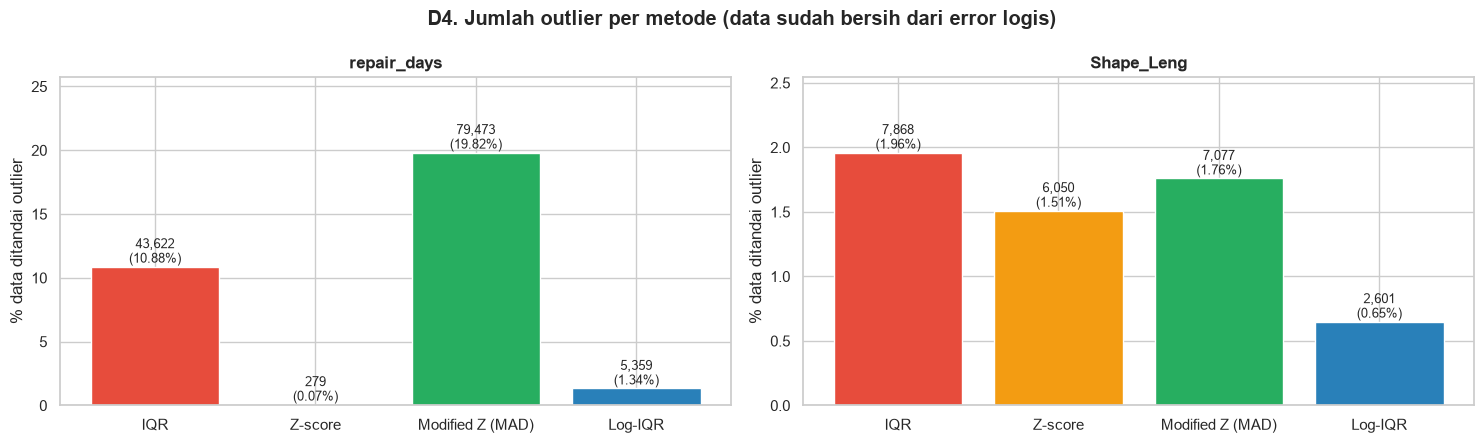

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
palette = dict(zip(METHODS, ["#e74c3c", "#f39c12", "#27ae60", "#2980b9"]))

for ax, col in zip(axes, ["repair_days", "Shape_Leng"]):
    t = outlier_table.query("kolom == @col")
    bars = ax.bar(t["metode"], t["% data"], color=[palette[m] for m in t["metode"]])
    ax.bar_label(bars, labels=[f"{n:,}\n({p}%)" for n, p in zip(t["n_outlier"], t["% data"])], fontsize=9)
    ax.set_title(f"{col}")
    ax.set_ylabel("% data ditandai outlier")
    ax.set_ylim(0, t["% data"].max() * 1.3)
fig.suptitle("D4. Jumlah outlier per metode (data sudah bersih dari error logis)", fontweight="bold")
plt.tight_layout()
savefig("D4_outlier_by_method")
plt.show()

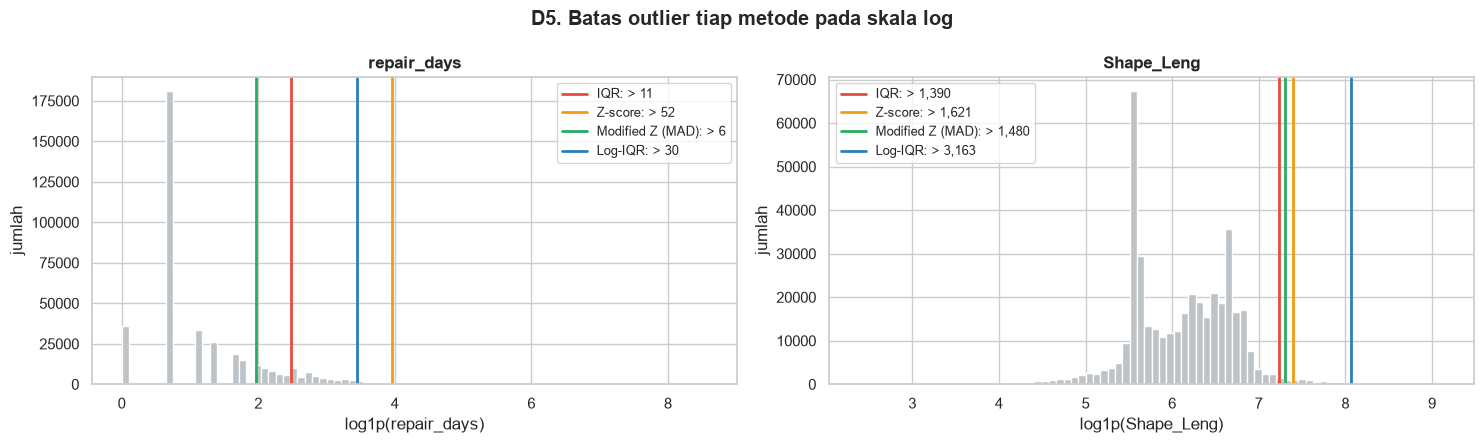

In [45]:
# Distribusi repair_days (log) dengan batas atas tiap metode
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ["repair_days", "Shape_Leng"]):
    ax.hist(np.log1p(df[col]), bins=80, color="#bdc3c7")
    for _, r in outlier_table.query("kolom == @col").iterrows():
        ax.axvline(np.log1p(r["batas_atas"]), color=palette[r["metode"]], lw=2,
                   label=f"{r['metode']}: > {r['batas_atas']:,.0f}")
    ax.set_xlabel(f"log1p({col})"); ax.set_ylabel("jumlah")
    ax.legend(fontsize=9)
    ax.set_title(col)
fig.suptitle("D5. Batas outlier tiap metode pada skala log", fontweight="bold")
plt.tight_layout()
savefig("D5_outlier_thresholds")
plt.show()

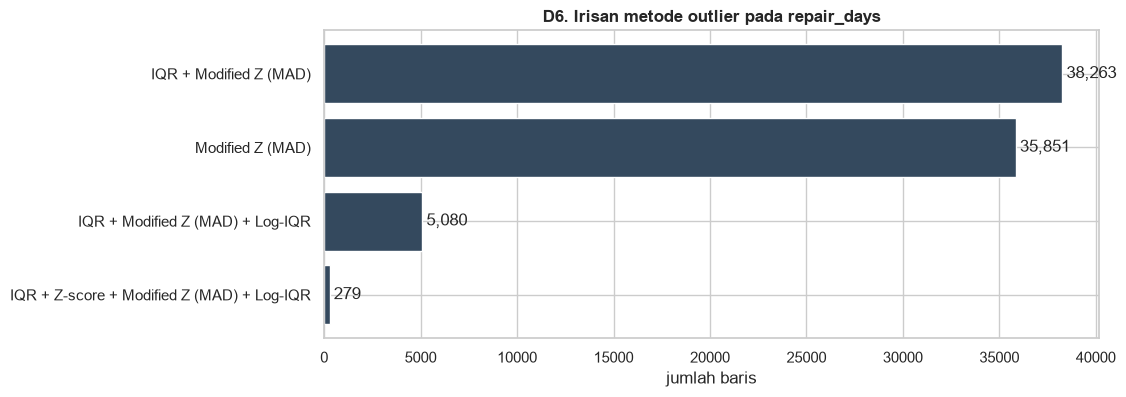

Ditandai oleh SEMUA 4 metode: 279 baris


In [46]:
# Irisan metode pada repair_days: kombinasi metode mana saja yang menandai sebuah baris
combo = pd.DataFrame({m: flags[("repair_days", m)] for m in METHODS})
pattern = combo.apply(lambda r: " + ".join([m for m in METHODS if r[m]]) or "(tidak ada)", axis=1)
pc = pattern.value_counts()
pc = pc[pc.index != "(tidak ada)"].head(8)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(pc.index[::-1], pc.values[::-1], color="#34495e")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
ax.set_xlabel("jumlah baris")
ax.set_title("D6. Irisan metode outlier pada repair_days")
savefig("D6_outlier_overlap")
plt.show()

print("Ditandai oleh SEMUA 4 metode:", combo.all(axis=1).sum(), "baris")

**Interpretasi:**
- **IQR biasa** (batas ±11 hari) menandai sekitar 11% data karena distribusinya sangat miring: perbaikan yang lebih dari 11 hari dianggap "outlier", padahal itu normal.
- **Z-score** (batas ±52 hari) justru terlalu longgar. Mean dan std-nya sendiri sudah tertarik oleh nilai ekstrem (efek *masking*).
- **MAD** paling agresif (batas ±6 hari, sekitar 20% data) karena lebih dari separuh perbaikan selesai dalam 0–1 hari, sehingga MAD-nya sangat kecil.
- **Log-IQR** (batas ±30 hari, sekitar 1,3% data) paling sesuai untuk data durasi, karena distribusinya mendekati simetris setelah transformasi log.
- Pada `Shape_Leng` yang skewness-nya lebih rendah (4,0), keempat metode memberi hasil yang lebih berdekatan (0,6–2%).
- **Isolation Forest** menangkap kombinasi yang janggal (misalnya segmen pendek dengan perbaikan sangat lama di lokasi tertentu), bukan hanya nilai ekstrem satu kolom.

### 10.3 Keputusan penanganan
| Kondisi | Keputusan | Alasan |
|---|---|---|
| `repair_days > 365` | **Hapus** | Work order yang lupa ditutup; durasi tidak mencerminkan perbaikan |
| `repair_days` di atas batas Log-IQR tapi ≤ 365 | **Pertahankan** + flag `repair_outlier` | Perbaikan lama tetap kejadian nyata; winsorize p99 hanya saat PCA |
| `repair_days == 0` | **Pertahankan** | Perbaikan di hari yang sama itu wajar, bukan outlier |
| `Shape_Leng > 5.000 ft` | **Pertahankan** + flag `long_segment` | Parkway/boulevard memang panjang (mis. Cross Bay Blvd) |
| Isolation Forest | **Flag saja** (`iforest_outlier`) | Multivariat, dipakai sebagai informasi, tidak dijadikan dasar penghapusan |

In [47]:
df_before_outlier = df[["repair_days", "Shape_Leng"]].copy()

df["repair_outlier"]  = flags[("repair_days", "Log-IQR")]
df["long_segment"]    = df["Shape_Leng"] > 5000
df["iforest_outlier"] = flags[("multivariat", "Isolation Forest")]

df = df[df["repair_days"] <= 365]
log("3.8b repair_days > 365", df)

df[["repair_outlier", "long_segment", "iforest_outlier"]].sum().rename("jumlah flag").to_frame()

[3.8b repair_days > 365] rows=400,961 cols=27

,jumlah flag
repair_outlier,5307
long_segment,122
iforest_outlier,4006


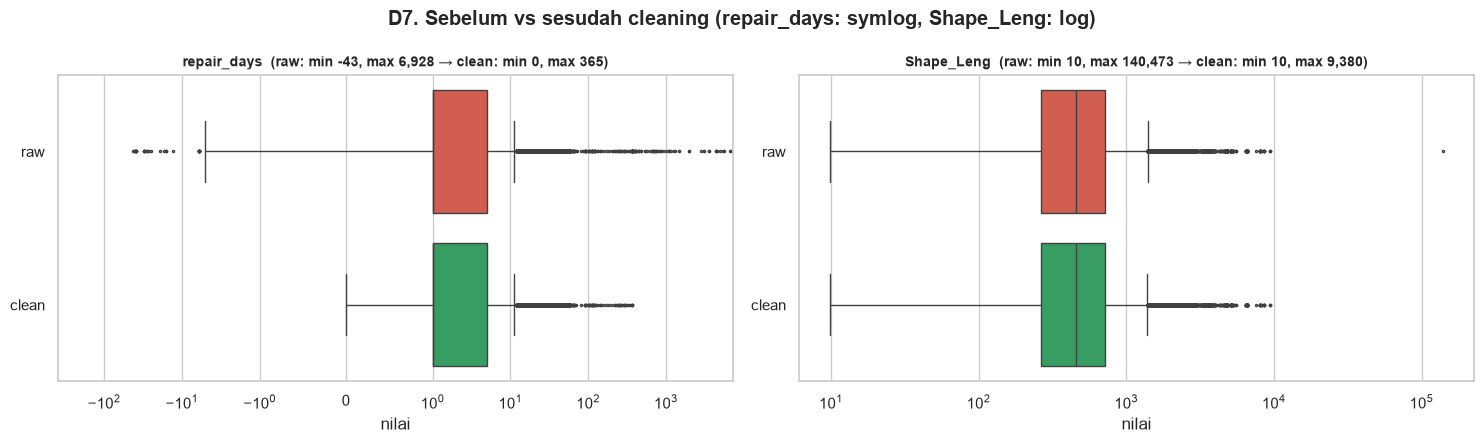

In [48]:
raw_rd = (pothole_raw.assign(r=pd.to_datetime(pothole_raw["RptClosed"], format=fmt)
                              - pd.to_datetime(pothole_raw["RptDate"], format=fmt))["r"].dt.days)
compare = {
    "repair_days": (raw_rd, df["repair_days"]),
    "Shape_Leng":  (pothole_raw["Shape_Leng"], df["Shape_Leng"]),
}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (col, (before, after)) in zip(axes, compare.items()):
    data = pd.DataFrame({"nilai": pd.concat([before, after], ignore_index=True),
                         "tahap": ["raw"] * len(before) + ["clean"] * len(after)})
    sns.boxplot(data=data, x="nilai", y="tahap", hue="tahap", ax=ax, fliersize=1.5,
                palette={"raw": "#e74c3c", "clean": "#27ae60"}, legend=False)
    if col == "repair_days":
        ax.set_xscale("symlog", linthresh=1)   # ada nilai negatif & nol di data raw
    else:
        ax.set_xscale("log")
    ax.set_title(f"{col}  (raw: min {before.min():,.0f}, max {before.max():,.0f} → "
                 f"clean: min {after.min():,.0f}, max {after.max():,.0f})", fontsize=10)
    ax.set_ylabel("")
fig.suptitle("D7. Sebelum vs sesudah cleaning (repair_days: symlog, Shape_Leng: log)", fontweight="bold")
plt.tight_layout()
savefig("D7_boxplot_before_after")
plt.show()

## 11. Cleaning Data Cuaca (plan 3.9)

Validasi struktural sudah lolos semua (bagian 3). Di sini nilainya **diverifikasi terhadap data observasi stasiun NOAA Central Park** (GHCN-Daily `USW00094728`) sebagai sumber referensi. Open-Meteo adalah data **model/reanalysis grid**, bukan pengukuran langsung.

> File referensi: `reference/noaa_centralpark_2018_2024.csv`. Jika belum ada, file diunduh otomatis dari NOAA NCEI API dengan `units=metric`, sehingga **PRCP dan SNOW dalam mm**, suhu dalam °C. Perhatikan bedanya: Open-Meteo memberi salju dalam **cm**, sedangkan NOAA dalam **mm**. Karena itu kolom NOAA diberi nama eksplisit `noaa_snow_mm` dan **tidak dipakai** untuk koreksi — hanya `PRCP` (sama-sama mm dengan `precipitation_sum`) yang dibandingkan dan dipakai mengoreksi, sehingga tidak ada konversi satuan yang tersembunyi.

In [49]:
NOAA_PATH = Path("reference/noaa_centralpark_2018_2024.csv")
NOAA_URL = ("https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries"
            "&stations=USW00094728&startDate=2018-01-01&endDate=2024-12-31"
            "&dataTypes=PRCP,SNOW,TMAX,TMIN&units=metric&format=csv")
if not NOAA_PATH.exists():
    NOAA_PATH.parent.mkdir(exist_ok=True)
    pd.read_csv(NOAA_URL).to_csv(NOAA_PATH, index=False)

noaa = (pd.read_csv(NOAA_PATH, parse_dates=["DATE"])
          .rename(columns={"DATE": "date", "PRCP": "noaa_precip", "SNOW": "noaa_snow_mm",
                           "TMAX": "noaa_tmax", "TMIN": "noaa_tmin"}))

weather = weather_raw.rename(columns={"time": "date"})
weather["date"] = pd.to_datetime(weather["date"], format="%Y-%m-%d")
cmp = weather.merge(noaa.drop(columns="STATION"), on="date", how="left", validate="one_to_one")
print("Hari tanpa pasangan NOAA:", cmp["noaa_precip"].isna().sum())

agree = pd.Series({
    "r suhu max":   cmp["temperature_2m_max"].corr(cmp["noaa_tmax"]),
    "r suhu min":   cmp["temperature_2m_min"].corr(cmp["noaa_tmin"]),
    "r presipitasi": cmp["precipitation_sum"].corr(cmp["noaa_precip"]),
}).round(3)
agree.to_frame("korelasi Open-Meteo vs NOAA")

Hari tanpa pasangan NOAA: 0


,korelasi Open-Meteo vs NOAA
r suhu max,0.99
r suhu min,0.98
r presipitasi,0.77


### 11.1 Uji keselarasan tanggal antar sumber

Dua sumber cuaca bisa saja **bergeser satu hari** kalau memakai zona waktu berbeda (mis. hari UTC vs hari lokal New York). Kalau itu terjadi, seluruh integrasi jadi salah tanggal.

Uji: geser data NOAA beberapa hari (*lag*), lalu lihat pada lag berapa korelasinya paling tinggi. **Kalau tanggal sudah sejajar, lag 0 harus menang.**

In [50]:
lag_test = pd.DataFrame([
    {"lag (hari)": L,
     "presipitasi": cmp["precipitation_sum"].corr(cmp["noaa_precip"].shift(L)),
     "suhu max":    cmp["temperature_2m_max"].corr(cmp["noaa_tmax"].shift(L)),
     "suhu min":    cmp["temperature_2m_min"].corr(cmp["noaa_tmin"].shift(L))}
    for L in range(-3, 4)]).set_index("lag (hari)").round(3)
display(lag_test)

best = {c: int(lag_test[c].idxmax()) for c in lag_test.columns}
print("Lag dengan korelasi tertinggi:", best)
assert set(best.values()) == {0}, "Tanggal antar sumber tidak sejajar!"
print("✓ Semua variabel paling cocok di lag 0 → penanggalan kedua sumber sudah sejajar (tidak ada geser zona waktu).")

,presipitasi,suhu max,suhu min
lag (hari),,,
-3,-0.01,0.81,0.85
-2,-0.04,0.83,0.87
-1,0.06,0.90,0.92
0,0.77,0.99,0.98
1,0.15,0.90,0.95
2,-0.03,0.84,0.90
3,-0.02,0.82,0.87


Lag dengan korelasi tertinggi: {'presipitasi': 0, 'suhu max': 0, 'suhu min': 0}
✓ Semua variabel paling cocok di lag 0 → penanggalan kedua sumber sudah sejajar (tidak ada geser zona waktu).


Semua variabel memuncak di **lag 0**, dan korelasi suhu sangat tinggi (≈0,99). Jadi penanggalan Open-Meteo dan NOAA memang mengacu pada **hari lokal yang sama**, sehingga aman digabungkan dengan `RptDate` pothole.

Korelasi presipitasi (≈0,77) lebih rendah daripada suhu bukan karena salah tanggal, melainkan karena hujan **jauh lebih bervariasi secara spasial**: NOAA mengukur di satu titik (Central Park), sedangkan Open-Meteo adalah rata-rata sel grid. Suhu jauh lebih seragam di seluruh kota, sehingga korelasinya mendekati sempurna.

In [51]:
cmp["diff"] = cmp["precipitation_sum"] - cmp["noaa_precip"]

# Aturan error: model melebih-lebihkan secara ekstrem (selisih > 30 mm DAN > 3x nilai observasi)
over = (cmp["diff"] > 30) & (cmp["precipitation_sum"] > 3 * (cmp["noaa_precip"] + 1))
under = (cmp["diff"] < -30)
print("Hari over-estimate ekstrem :", over.sum())
print("Hari under-estimate > 30 mm:", under.sum())
display(cmp.loc[over | under, ["date", "precipitation_sum", "noaa_precip", "diff", "snowfall_sum"]]
          .sort_values("diff"))

Hari over-estimate ekstrem : 3
Hari under-estimate > 30 mm: 11


,date,precipitation_sum,noaa_precip,diff,snowfall_sum
1328,2021-08-21,1.20,113.00,-111.80,0.00
1339,2021-09-01,111.50,181.10,-69.60,0.00
2097,2023-09-29,69.90,139.20,-69.30,0.00
222,2018-08-11,12.50,73.70,-61.20,0.00
1284,2021-07-08,12.20,57.70,-45.50,0.00
2079,2023-09-11,4.40,42.20,-37.80,0.00
954,2020-08-12,7.60,44.70,-37.10,0.00
1945,2023-04-30,22.20,58.90,-36.70,0.00
1659,2022-07-18,13.00,47.00,-34.00,0.00
933,2020-07-22,3.40,36.10,-32.70,0.00


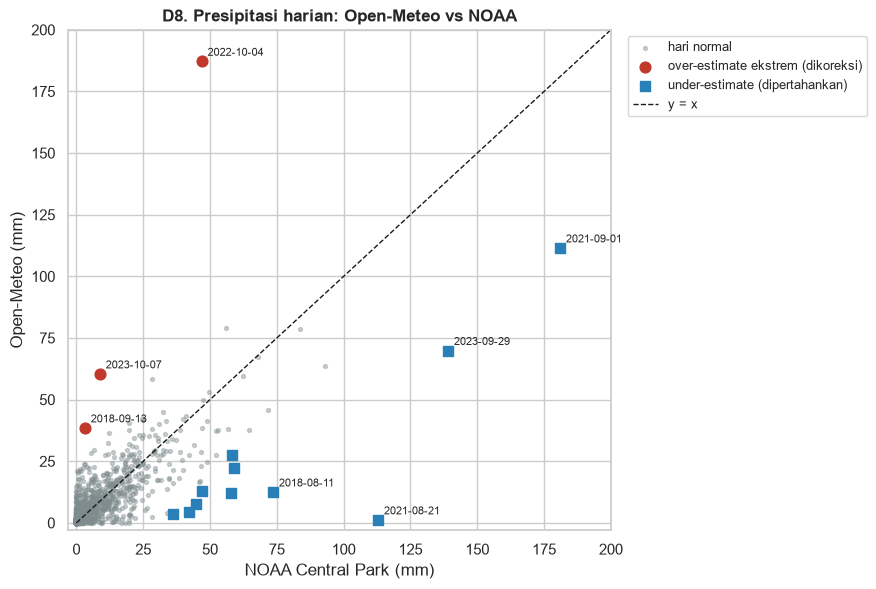

In [52]:
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(cmp["noaa_precip"], cmp["precipitation_sum"], s=8, alpha=.4, color="#7f8c8d", label="hari normal")
ax.scatter(cmp.loc[over, "noaa_precip"], cmp.loc[over, "precipitation_sum"], s=60, color="#c0392b",
           label="over-estimate ekstrem (dikoreksi)")
ax.scatter(cmp.loc[under, "noaa_precip"], cmp.loc[under, "precipitation_sum"], s=60, color="#2980b9",
           marker="s", label="under-estimate (dipertahankan)")
for _, r in cmp[over | (cmp["diff"] < -60)].iterrows():   # label hanya kasus terbesar agar tidak menumpuk
    ax.annotate(r["date"].strftime("%Y-%m-%d"), (r["noaa_precip"], r["precipitation_sum"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
lim = 200
ax.plot([0, lim], [0, lim], "k--", lw=1, label="y = x")
ax.set_xlim(-3, lim); ax.set_ylim(-3, lim)
ax.set_xlabel("NOAA Central Park (mm)"); ax.set_ylabel("Open-Meteo (mm)")
ax.set_title("D8. Presipitasi harian: Open-Meteo vs NOAA")
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.02, 1))
savefig("D8_weather_vs_noaa")
plt.show()

In [53]:
# Alternatif penanganan untuk 2022-10-04: bandingkan hasilnya dengan nilai observasi
w_idx = weather.set_index("date")
bad_day = pd.Timestamp("2022-10-04")
interp_val = w_idx["precipitation_sum"].mask(w_idx.index == bad_day).interpolate().loc[bad_day]
alt = pd.Series({
    "nilai asli Open-Meteo":        w_idx.loc[bad_day, "precipitation_sum"],
    "hapus lalu interpolasi linear": round(interp_val, 1),
    "ganti median bulan Oktober":   w_idx.loc[w_idx.index.month == 10, "precipitation_sum"].median(),
    "observasi NOAA (acuan)":       noaa.set_index("date").loc[bad_day, "noaa_precip"],
})
alt.to_frame("presipitasi 2022-10-04 (mm)")

,presipitasi 2022-10-04 (mm)
nilai asli Open-Meteo,187.20
hapus lalu interpolasi linear,13.20
ganti median bulan Oktober,0.10
observasi NOAA (acuan),47.00


**Keputusan:** Interpolasi dan median sama-sama **meremehkan** kejadian hujan lebat pada hari itu, padahal hari itu memang hujan lebat (47 mm menurut NOAA). Karena itu, hari yang terbukti *over-estimate* ekstrem **dikoreksi dengan nilai observasi NOAA**. Ini adalah koreksi berbasis sumber referensi, bukan tebakan statistik. `rain_sum` ikut disamakan karena pada hari-hari tersebut tidak ada salju.

Hari *under-estimate* (mis. Badai Ida 2021-09-01: model 111,5 mm vs stasiun 181,1 mm) **tidak diubah**. Nilainya memang ekstrem dan nyata; model grid hanya memperhalus hujan badai lokal. Keterbatasan ini dicatat di laporan.

Deteksi outlier statistik biasa (IQR) **tidak cocok** untuk presipitasi, seperti ditunjukkan di bawah.

In [54]:
p = weather["precipitation_sum"]
m_iqr, up = flag_iqr(p)
print(f"IQR pada presipitasi: batas atas {up:.1f} mm, dan {m_iqr.sum()} hari ({m_iqr.mean()*100:.1f}%) ditandai outlier")
print(f"Padahal {(p == 0).mean()*100:.1f}% hari bernilai 0, jadi semua hari hujan sedang ikut dianggap 'outlier'")

IQR pada presipitasi: batas atas 8.5 mm, dan 375 hari (14.7%) ditandai outlier
Padahal 46.3% hari bernilai 0, jadi semua hari hujan sedang ikut dianggap 'outlier'


In [55]:
weather_clean = weather.copy()
assert (weather_clean.loc[over, "snowfall_sum"] == 0).all()
weather_clean["precip_corrected"] = over
weather_clean.loc[over, "precipitation_sum"] = cmp.loc[over, "noaa_precip"].values
weather_clean.loc[over, "rain_sum"] = cmp.loc[over, "noaa_precip"].values

# Validasi ulang setelah koreksi
assert (weather_clean["rain_sum"] <= weather_clean["precipitation_sum"]).all()
assert (weather_clean["temperature_2m_min"] <= weather_clean["temperature_2m_max"]).all()
display(weather_clean.loc[over])

,date,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,snowfall_sum,precip_corrected
255,2018-09-13,24.90,20.80,3.30,3.30,0.00,True
1737,2022-10-04,12.90,8.40,47.00,47.00,0.00,True
2105,2023-10-07,20.70,11.80,8.90,8.90,0.00,True


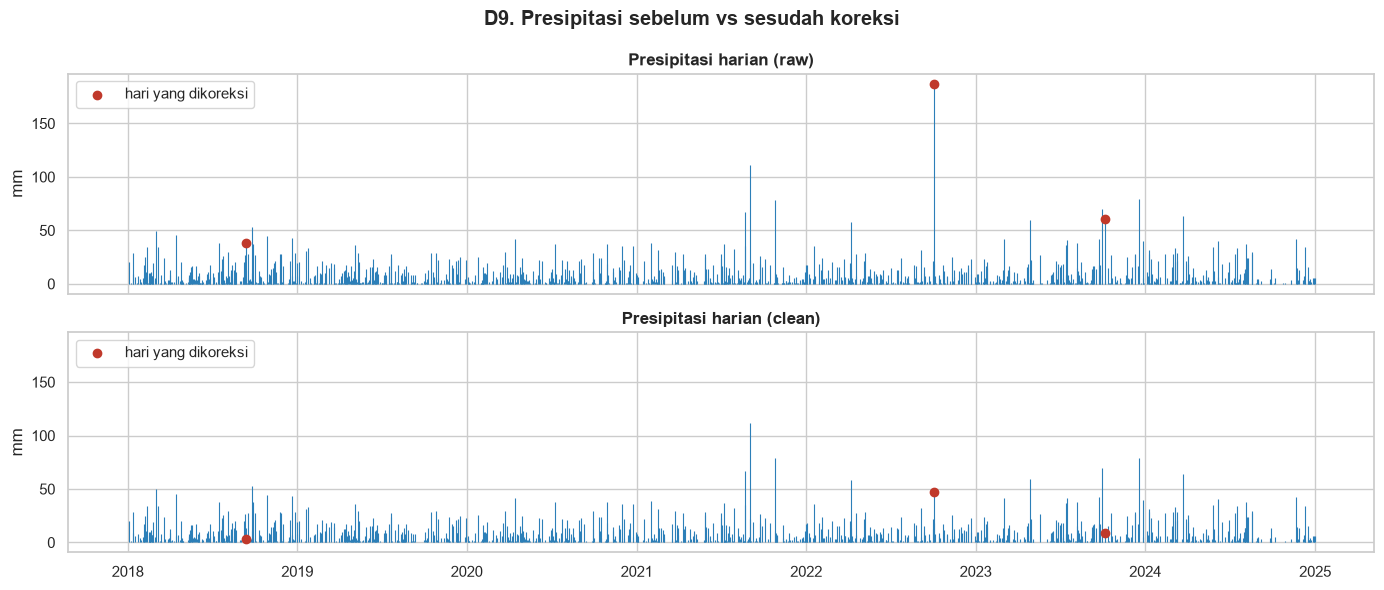

In [56]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
for ax, (label, d) in zip(axes, [("raw", weather), ("clean", weather_clean)]):
    ax.vlines(d["date"], 0, d["precipitation_sum"], color="#2c7fb8", lw=.8)
    ax.scatter(d.loc[over, "date"], d.loc[over, "precipitation_sum"], color="#c0392b", zorder=3,
               label="hari yang dikoreksi")
    ax.set_title(f"Presipitasi harian ({label})"); ax.set_ylabel("mm")
    ax.legend(loc="upper left")
fig.suptitle("D9. Presipitasi sebelum vs sesudah koreksi", fontweight="bold")
plt.tight_layout()
savefig("D9_weather_before_after")
plt.show()

## 12. Ringkasan & Simpan (plan 3.10)

,step,rows,cols,baris_dihapus,kolom_berubah
0,raw,410488,15,0,0
1,3.3 tipe data,410488,15,0,0
2,3.6 hapus duplikat logis,401635,23,8853,8
3,3.7 feature engineering & drop kolom,401635,24,0,1
4,3.8a repair_days < 0 (ditutup sebelum dilaporkan),401061,24,574,0
5,3.8a RptDate < 2010 (sisa sistem lama),401016,24,45,0
6,3.8a Tanggal di masa depan,401016,24,0,0
7,3.8a Koordinat di luar NYC,401016,24,0,0
8,3.8a Shape_Leng <= 0,401016,24,0,0
9,3.8a Segmen 'BODY OF WATER' (bukan jalan),401013,24,3,0


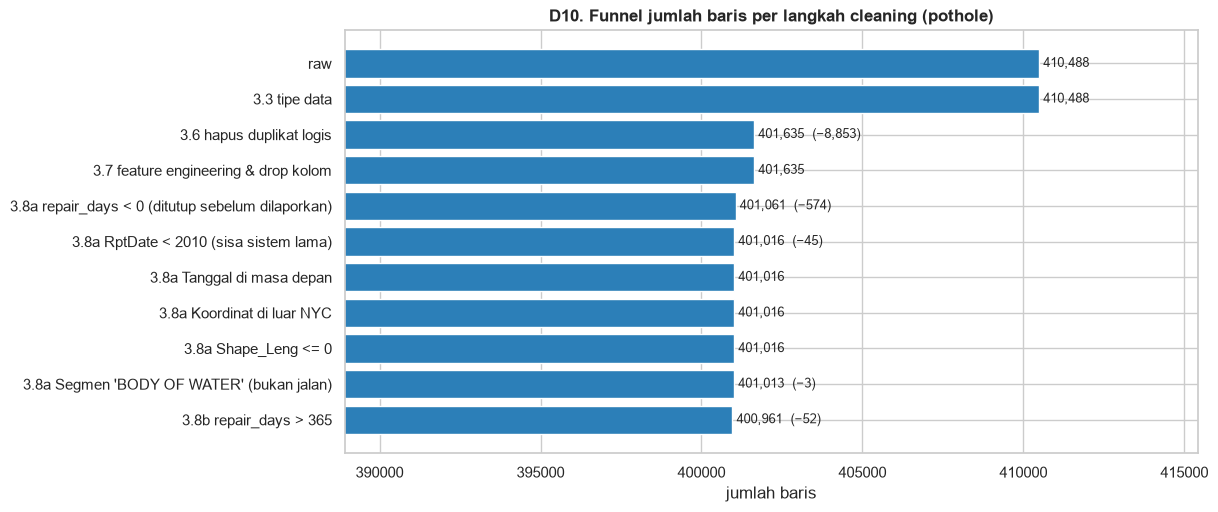

Total dihapus: 9,527 baris (2.32%)


In [57]:
steps = pd.DataFrame(log_steps)
steps["baris_dihapus"] = (-steps["rows"].diff()).fillna(0).astype(int)
steps["kolom_berubah"] = steps["cols"].diff().fillna(0).astype(int)
display(steps)

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(steps["step"][::-1], steps["rows"][::-1], color="#2c7fb8")
ax.bar_label(bars, labels=[f"{r:,}  (−{d:,})" if d else f"{r:,}"
                           for r, d in zip(steps["rows"][::-1], steps["baris_dihapus"][::-1])], padding=3, fontsize=9)
ax.set_xlim(steps["rows"].min() * 0.97, steps["rows"].max() * 1.012)
ax.set_xlabel("jumlah baris")
ax.set_title("D10. Funnel jumlah baris per langkah cleaning (pothole)")
savefig("D10_cleaning_funnel")
plt.show()

removed = steps["rows"].iloc[0] - steps["rows"].iloc[-1]
print(f"Total dihapus: {removed:,} baris ({removed / steps['rows'].iloc[0] * 100:.2f}%)")

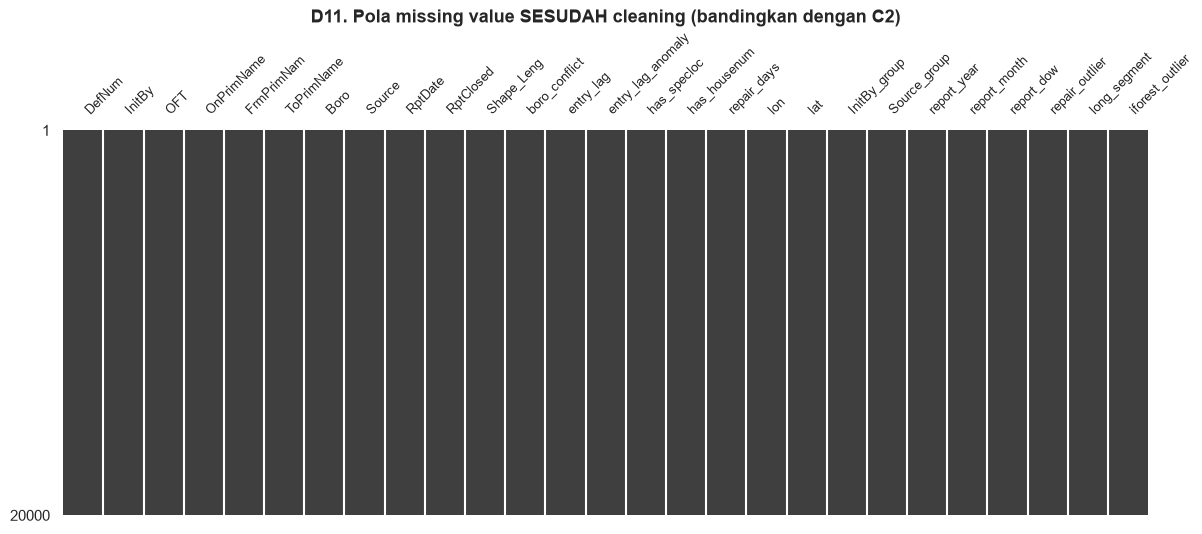

Total NaN tersisa: 0


In [58]:
ax = msno.matrix(df.sample(20_000, random_state=RANDOM_STATE).sort_values("RptDate"),
                 figsize=(14, 5), fontsize=9, sparkline=False)
ax.set_title("D11. Pola missing value SESUDAH cleaning (bandingkan dengan C2)", fontsize=13)
savefig("D11_missingno_clean")
plt.show()
print("Total NaN tersisa:", int(df.isna().sum().sum()))

In [59]:
df = df.reset_index(drop=True)
df.to_parquet(OUT_DIR / "pothole_clean.parquet", index=False)
df.to_csv(OUT_DIR / "pothole_clean.csv", index=False, date_format="%Y-%m-%d")   # versi CSV untuk dibuka di Excel / dikumpulkan
weather_clean.to_csv(OUT_DIR / "weather_clean.csv", index=False, date_format="%Y-%m-%d")
steps.to_csv(OUT_DIR / "cleaning_log.csv", index=False)

check = pd.read_parquet(OUT_DIR / "pothole_clean.parquet")
print("pothole_clean.parquet :", check.shape, "| NaN:", int(check.isna().sum().sum()))
print("weather_clean.csv     :", weather_clean.shape)
print("Baris pothole di periode cuaca (2018–2024):",
      check["RptDate"].between("2018-01-01", "2024-12-31").sum())

pothole_clean.parquet : (400961, 27) | NaN: 0
weather_clean.csv     : (2557, 7)
Baris pothole di periode cuaca (2018–2024): 145279


Data disimpan dalam dua format: **Parquet** (dipakai notebook berikutnya, karena tipe data ikut tersimpan) dan **CSV** (agar mudah dibuka/dikumpulkan). Saat membaca versi CSV, tipe data harus ditentukan manual, misalnya `dtype={"OFT": "string"}` dan `parse_dates=["RptDate", "RptClosed"]`.

> ⚠️ Jangan membuka lalu **menyimpan ulang** CSV ini di Excel: Excel hanya menyimpan 15 digit, sehingga `OFT` (18 digit) akan rusak.

**Output cleaning:**
| File | Isi |
|---|---|
| `output/pothole_clean.parquet` | Data work order bersih (1 baris = 1 work order), semua tahun. **Dipakai notebook berikutnya** |
| `output/pothole_clean.csv` | Isi sama, format CSV (untuk Excel / pengumpulan) |
| `output/weather_clean.csv` | Cuaca harian 2018–2024 + flag `precip_corrected` |
| `output/cleaning_log.csv` | Jumlah baris per langkah |
| `output/data_quality_issues.csv` | Issue register dari profiling |

**Langkah berikutnya:** `data_integration.ipynb`, yaitu filter 2018–2024, agregasi harian per borough, merge dengan cuaca, lalu analisis atribut redundan.